In [5]:
# =============================================================================
# STEP 0 : IMPORT LIBRARIES
# =============================================================================

import os
import re
import glob
import warnings
from pathlib import Path
from itertools import combinations

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from scipy import stats
from scipy.stats import (
    shapiro,
    levene,
    f_oneway,
    kruskal,
    friedmanchisquare,
    wilcoxon,
    t
)

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    classification_report
)
from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.lines import Line2D
import seaborn as sns

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 11
sns.set_style("whitegrid")

print("=" * 80)
print("STEP 0 : LIBRARIES IMPORTED SUCCESSFULLY")
print("=" * 80)


STEP 0 : LIBRARIES IMPORTED SUCCESSFULLY


In [6]:
# =============================================================================
# STEP 1 : DEFINE PROJECT PATHS AND CREATE OUTPUT DIRECTORIES
# =============================================================================

from pathlib import Path

# -----------------------------------------------------------------------------
# INPUT: BENCHMARK RESULTS
# -----------------------------------------------------------------------------

BASE_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results"
)

CNN_BENCHMARK_DIR = (
    BASE_DIR / "CNN_Results" / "Evaluation" / "Benchmark"
)

VIT_BENCHMARK_DIR = (
    BASE_DIR / "VisionTransformer_Results" / "Benchmark"
)

# -----------------------------------------------------------------------------
# INPUT: TRAINING SUMMARY FILES
# -----------------------------------------------------------------------------

CNN_TRAINING_FILE = (
    BASE_DIR / "CNN_Results" / "Saved_Models" / "training_summary.csv"
)

VIT_TRAINING_FILE = (
    BASE_DIR / "VisionTransformer_Results"
    / "VisionTransformer_Benchmark_Results.csv"
)

# -----------------------------------------------------------------------------
# INPUT: PER-IMAGE PREDICTION TABLES
# -----------------------------------------------------------------------------

CNN_PREDICTIONS_DIR = (
    BASE_DIR / "CNN_Results" / "Evaluation" / "Predictions"
)

VIT_PREDICTIONS_DIR = (
    BASE_DIR / "VisionTransformer_Results"
    / "Evaluation" / "Predictions"
)

# -----------------------------------------------------------------------------
# FINAL OUTPUT DIRECTORY
# -----------------------------------------------------------------------------

OUTPUT_DIR = BASE_DIR / "Final_Benchmark"

TABLES_DIR = OUTPUT_DIR / "01_Tables"
FIGURES_DIR = OUTPUT_DIR / "02_Figures"
STATISTICS_DIR = OUTPUT_DIR / "03_Statistics"
ROC_DIR = OUTPUT_DIR / "04_ROC"
CM_DIR = OUTPUT_DIR / "05_Confusion_Matrices"
CONFIDENCE_DIR = OUTPUT_DIR / "06_Confidence_Analysis"
EFFICIENCY_DIR = OUTPUT_DIR / "07_Computational_Efficiency"
CLASSWISE_DIR = OUTPUT_DIR / "08_Classwise_Analysis"
SUMMARY_DIR = OUTPUT_DIR / "09_Summary"

for folder in [
    OUTPUT_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    STATISTICS_DIR,
    ROC_DIR,
    CM_DIR,
    CONFIDENCE_DIR,
    EFFICIENCY_DIR,
    CLASSWISE_DIR,
    SUMMARY_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

# One canonical file used later in the pipeline
TRAINING_SUMMARY_OUTPUT = OUTPUT_DIR / "Training_Time_Summary.csv"

print("=" * 80)
print("STEP 1 : PROJECT PATHS")
print("=" * 80)
print(f"CNN benchmark directory       : {CNN_BENCHMARK_DIR}")
print(f"ViT benchmark directory       : {VIT_BENCHMARK_DIR}")
print(f"CNN training summary          : {CNN_TRAINING_FILE}")
print(f"ViT training summary          : {VIT_TRAINING_FILE}")
print(f"CNN prediction directory     : {CNN_PREDICTIONS_DIR}")
print(f"ViT prediction directory     : {VIT_PREDICTIONS_DIR}")
print(f"Final output directory       : {OUTPUT_DIR}")
print("\n✓ All output directories created.")


STEP 1 : PROJECT PATHS
CNN benchmark directory       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Benchmark
ViT benchmark directory       : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark
CNN training summary          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\training_summary.csv
ViT training summary          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Benchmark_Results.csv
CNN prediction directory     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions
ViT prediction directory     : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evalu

In [7]:
# =============================================================================
# STEP 2 : DISCOVER ALL BENCHMARK FILES
# =============================================================================

import re

# -----------------------------------------------------------------------------
# Find all per-run benchmark CSV files
# -----------------------------------------------------------------------------

cnn_csv_files = sorted(
    CNN_BENCHMARK_DIR.glob("*_Run*_Benchmark_Summary.csv")
)

vit_csv_files = sorted(
    VIT_BENCHMARK_DIR.glob("*_Run*_Benchmark_Summary.csv")
)

print("=" * 80)
print("BENCHMARK FILE DISCOVERY")
print("=" * 80)

print(f"\nCNN Benchmark Files Found : {len(cnn_csv_files)}")
for file in cnn_csv_files:
    print(f"  ✓ {file.name}")

print(f"\nVision Transformer Benchmark Files Found : {len(vit_csv_files)}")
for file in vit_csv_files:
    print(f"  ✓ {file.name}")

# -----------------------------------------------------------------------------
# Create Benchmark File Summary
# -----------------------------------------------------------------------------

benchmark_files = []

# ---------------- CNN ----------------

for file in cnn_csv_files:

    match = re.match(
        r"(.*)_Run(\d+)_Benchmark_Summary",
        file.stem
    )

    if match is None:
        continue

    benchmark_files.append({

        "Model": match.group(1),

        "Run": int(match.group(2)),

        "Family": "CNN",

        "Filename": file.name,

        "Path": file

    })

# -------- Vision Transformer ---------

for file in vit_csv_files:

    match = re.match(
        r"(.*)_Run(\d+)_Benchmark_Summary",
        file.stem
    )

    if match is None:
        continue

    benchmark_files.append({

        "Model": match.group(1),

        "Run": int(match.group(2)),

        "Family": "Vision Transformer",

        "Filename": file.name,

        "Path": file

    })

benchmark_files_df = pd.DataFrame(benchmark_files)

if benchmark_files_df.empty:
    raise FileNotFoundError(
        "No benchmark summary CSV files were discovered.\n"
        f"CNN directory checked: {CNN_BENCHMARK_DIR}\n"
        f"ViT directory checked: {VIT_BENCHMARK_DIR}\n"
        "Expected filename pattern: *_Run*_Benchmark_Summary.csv"
    )

# -----------------------------------------------------------------------------
# Sort for Better Readability
# -----------------------------------------------------------------------------

benchmark_files_df = benchmark_files_df.sort_values(
    ["Family", "Model", "Run"]
).reset_index(drop=True)

# -----------------------------------------------------------------------------
# Display Summary
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("BENCHMARK FILE SUMMARY")
print("=" * 80)

display(
    benchmark_files_df[
        ["Model", "Run", "Family", "Filename"]
    ]
)

print(f"\nTotal Benchmark Files : {len(benchmark_files_df)}")

BENCHMARK FILE DISCOVERY

CNN Benchmark Files Found : 25
  ✓ DenseNet121_Run1_Benchmark_Summary.csv
  ✓ DenseNet121_Run2_Benchmark_Summary.csv
  ✓ DenseNet121_Run3_Benchmark_Summary.csv
  ✓ DenseNet121_Run4_Benchmark_Summary.csv
  ✓ DenseNet121_Run5_Benchmark_Summary.csv
  ✓ EfficientNet_B0_Run1_Benchmark_Summary.csv
  ✓ EfficientNet_B0_Run2_Benchmark_Summary.csv
  ✓ EfficientNet_B0_Run3_Benchmark_Summary.csv
  ✓ EfficientNet_B0_Run4_Benchmark_Summary.csv
  ✓ EfficientNet_B0_Run5_Benchmark_Summary.csv
  ✓ EfficientNet_B1_Run1_Benchmark_Summary.csv
  ✓ EfficientNet_B1_Run2_Benchmark_Summary.csv
  ✓ EfficientNet_B1_Run3_Benchmark_Summary.csv
  ✓ EfficientNet_B1_Run4_Benchmark_Summary.csv
  ✓ EfficientNet_B1_Run5_Benchmark_Summary.csv
  ✓ MobileNetV3_Run1_Benchmark_Summary.csv
  ✓ MobileNetV3_Run2_Benchmark_Summary.csv
  ✓ MobileNetV3_Run3_Benchmark_Summary.csv
  ✓ MobileNetV3_Run4_Benchmark_Summary.csv
  ✓ MobileNetV3_Run5_Benchmark_Summary.csv
  ✓ ResNet50_Run1_Benchmark_Summary.csv
  ✓

,Model,Run,Family,Filename
0,DenseNet121,1,CNN,DenseNet121_Run1_Benchmark_Summary.csv
1,DenseNet121,2,CNN,DenseNet121_Run2_Benchmark_Summary.csv
2,DenseNet121,3,CNN,DenseNet121_Run3_Benchmark_Summary.csv
3,DenseNet121,4,CNN,DenseNet121_Run4_Benchmark_Summary.csv
4,DenseNet121,5,CNN,DenseNet121_Run5_Benchmark_Summary.csv
5,EfficientNet_B0,1,CNN,EfficientNet_B0_Run1_Benchmark_Summary.csv
6,EfficientNet_B0,2,CNN,EfficientNet_B0_Run2_Benchmark_Summary.csv
7,EfficientNet_B0,3,CNN,EfficientNet_B0_Run3_Benchmark_Summary.csv
8,EfficientNet_B0,4,CNN,EfficientNet_B0_Run4_Benchmark_Summary.csv
9,EfficientNet_B0,5,CNN,EfficientNet_B0_Run5_Benchmark_Summary.csv



Total Benchmark Files : 40


In [4]:
# =============================================================================
# STEP 3 : LOAD AND MERGE ALL BENCHMARK RESULTS
# =============================================================================

master_data = []

print("=" * 80)
print("LOADING BENCHMARK FILES")
print("=" * 80)

for _, row in benchmark_files_df.iterrows():

    try:
        # ---------------------------------------------------------------------
        # Read Benchmark CSV
        # ---------------------------------------------------------------------
        df = pd.read_csv(row["Path"])

        # ---------------------------------------------------------------------
        # Add Metadata
        # ---------------------------------------------------------------------
        df["Model"] = row["Model"]
        df["Run"] = row["Run"]
        df["Family"] = row["Family"]

        # ---------------------------------------------------------------------
        # Store
        # ---------------------------------------------------------------------
        master_data.append(df)

        print(f"✓ {row['Filename']}  ({len(df)} row)")

    except Exception as e:
        print(f"✗ Error loading {row['Filename']}")
        print(e)

# -----------------------------------------------------------------------------
# Merge All Data
# -----------------------------------------------------------------------------

master_df = pd.concat(master_data, ignore_index=True)

# -----------------------------------------------------------------------------
# Reorder Metadata Columns
# -----------------------------------------------------------------------------

meta_cols = ["Model", "Run", "Family"]

other_cols = [c for c in master_df.columns if c not in meta_cols]

master_df = master_df[meta_cols + other_cols]

# -----------------------------------------------------------------------------
# Display Information
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("MASTER DATASET CREATED")
print("=" * 80)

print(f"Total Rows      : {len(master_df)}")
print(f"Total Columns   : {master_df.shape[1]}")
print(f"Unique Models   : {master_df['Model'].nunique()}")
print(f"Families        : {master_df['Family'].unique()}")

print("\nModels")

display(
    master_df.groupby("Model")
             .size()
             .reset_index(name="Number of Runs")
)

print("\nPreview")

display(master_df.head())

# -----------------------------------------------------------------------------
# Save Master Dataset
# -----------------------------------------------------------------------------

master_csv = SUMMARY_DIR / "Master_Benchmark_Dataset.csv"

master_df.to_csv(master_csv, index=False)

print(f"\n✓ Master dataset saved to:\n{master_csv}")

LOADING BENCHMARK FILES
✓ DenseNet121_Run1_Benchmark_Summary.csv  (1 row)
✓ DenseNet121_Run2_Benchmark_Summary.csv  (1 row)
✓ DenseNet121_Run3_Benchmark_Summary.csv  (1 row)
✓ DenseNet121_Run4_Benchmark_Summary.csv  (1 row)
✓ DenseNet121_Run5_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B0_Run1_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B0_Run2_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B0_Run3_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B0_Run4_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B0_Run5_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B1_Run1_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B1_Run2_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B1_Run3_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B1_Run4_Benchmark_Summary.csv  (1 row)
✓ EfficientNet_B1_Run5_Benchmark_Summary.csv  (1 row)
✓ MobileNetV3_Run1_Benchmark_Summary.csv  (1 row)
✓ MobileNetV3_Run2_Benchmark_Summary.csv  (1 row)
✓ MobileNetV3_Run3_Benchmark_Summary.csv  (1 row)
✓ MobileNetV3_Run4_Benchmark_Summary

,Model,Number of Runs
0,DeiT_Small,5
1,DenseNet121,5
2,EfficientNet_B0,5
3,EfficientNet_B1,5
4,MobileNetV3,5
5,ResNet50,5
6,Swin_Tiny,5
7,ViT_Base,5



Preview


,Model,Run,Family,Total Images,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,...,Cohen Kappa,MCC,Log Loss,Parameters,Trainable Parameters,"Inference Time (Total, s)",Inference Time/Image (ms),Micro AUC,Macro AUC,Weighted AUC
0,DenseNet121,1,CNN,224,0.8080,0.8194,0.7841,0.7928,0.8132,0.8080,...,0.7803,0.7819,0.7734,8012160,8012160,10.5452,47.0768,0.9741,0.9712,0.9697
1,DenseNet121,2,CNN,224,0.7500,0.7569,0.7325,0.7400,0.7519,0.7500,...,0.7146,0.7153,0.8288,8012160,8012160,10.3111,46.0315,0.9635,0.9597,0.9600
2,DenseNet121,3,CNN,224,0.7991,0.7969,0.7850,0.7885,0.7978,0.7991,...,0.7710,0.7715,0.7030,8012160,8012160,10.3917,46.3914,0.9768,0.9724,0.9706
3,DenseNet121,4,CNN,224,0.7589,0.8197,0.7201,0.7378,0.7922,0.7589,...,0.7228,0.7267,0.8994,8012160,8012160,11.3301,50.5807,0.9710,0.9683,0.9679
4,DenseNet121,5,CNN,224,0.7411,0.7362,0.7258,0.7276,0.7415,0.7411,...,0.7048,0.7053,0.7467,8012160,8012160,11.1564,49.8053,0.9708,0.9656,0.9647



✓ Master dataset saved to:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\09_Summary\Master_Benchmark_Dataset.csv


In [9]:
# =============================================================================
# STEP 4 : DATA VALIDATION & QUALITY CHECK
# =============================================================================

print("=" * 80)
print("DATA VALIDATION")
print("=" * 80)

# -----------------------------------------------------------------------------
# Dataset Shape
# -----------------------------------------------------------------------------

print(f"Rows    : {master_df.shape[0]}")
print(f"Columns : {master_df.shape[1]}")

# -----------------------------------------------------------------------------
# Missing Values
# -----------------------------------------------------------------------------

print("\nMissing Values")

missing = master_df.isnull().sum()

display(
    missing[missing > 0]
)

if missing.sum() == 0:
    print("✓ No Missing Values Found")

# -----------------------------------------------------------------------------
# Duplicate Rows
# -----------------------------------------------------------------------------

duplicates = master_df.duplicated().sum()

print(f"\nDuplicate Rows : {duplicates}")

# -----------------------------------------------------------------------------
# Unique Models
# -----------------------------------------------------------------------------

print("\nModels")

display(
    master_df["Model"]
    .value_counts()
    .sort_index()
)

# -----------------------------------------------------------------------------
# Unique Families
# -----------------------------------------------------------------------------

print("\nModel Families")

display(
    master_df["Family"].value_counts()
)

# -----------------------------------------------------------------------------
# Run Validation
# -----------------------------------------------------------------------------

print("\nRun Validation")

run_summary = (
    master_df
    .groupby("Model")["Run"]
    .nunique()
    .reset_index(name="Runs")
)

display(run_summary)

expected_models = {
    "DenseNet121", "EfficientNet_B0", "EfficientNet_B1",
    "MobileNetV3", "ResNet50",
    "DeiT_Small", "Swin_Tiny", "ViT_Base"
}

missing_models = expected_models - set(master_df["Model"].unique())
unexpected_models = set(master_df["Model"].unique()) - expected_models

assert not missing_models, f"Missing expected models: {sorted(missing_models)}"
assert not unexpected_models, f"Unexpected model names found: {sorted(unexpected_models)}"
assert (run_summary["Runs"] == 5).all(),     "Some models do not have exactly 5 runs."

print("✓ All 8 expected models are present.")
print("✓ Every model contains exactly 5 runs.")

# -----------------------------------------------------------------------------
# Data Types
# -----------------------------------------------------------------------------

print("\nColumn Data Types")

display(master_df.dtypes)

print("\n✓ Dataset validation completed successfully.")

DATA VALIDATION
Rows    : 40
Columns : 22

Missing Values


Series([], dtype: int64)

✓ No Missing Values Found

Duplicate Rows : 0

Models


Model
DeiT_Small         5
DenseNet121        5
EfficientNet_B0    5
EfficientNet_B1    5
MobileNetV3        5
ResNet50           5
Swin_Tiny          5
ViT_Base           5
Name: count, dtype: int64


Model Families


...


Run Validation


,Model,Runs
0,DeiT_Small,5
1,DenseNet121,5
2,EfficientNet_B0,5
3,EfficientNet_B1,5
4,MobileNetV3,5
5,ResNet50,5
6,Swin_Tiny,5
7,ViT_Base,5


✓ All 8 expected models are present.
✓ Every model contains exactly 5 runs.

Column Data Types


Model                         object
Run                            int64
Family                        object
Total Images                   int64
Accuracy                     float64
Precision Macro              float64
Recall Macro                 float64
F1 Macro                     float64
Precision Weighted           float64
Recall Weighted              float64
F1 Weighted                  float64
Balanced Accuracy            float64
Cohen Kappa                  float64
MCC                          float64
Log Loss                     float64
Parameters                     int64
Trainable Parameters           int64
Inference Time (Total, s)    float64
Inference Time/Image (ms)    float64
Micro AUC                    float64
Macro AUC                    float64
Weighted AUC                 float64
dtype: object


✓ Dataset validation completed successfully.


In [7]:
# =============================================================================
# CREATE MASTER TRAINING SUMMARY CSV
# =============================================================================

import pandas as pd
from pathlib import Path

# -------------------------------------------------------------------------
# Paths
# -------------------------------------------------------------------------

CNN_FILE = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\training_summary.csv")

VIT_FILE = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Benchmark_Results.csv")

OUTPUT_FILE = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\Training_Time_Summary.csv")

# -------------------------------------------------------------------------
# Load CSVs
# -------------------------------------------------------------------------

cnn = pd.read_csv(CNN_FILE)
vit = pd.read_csv(VIT_FILE)

# -------------------------------------------------------------------------
# Add Family
# -------------------------------------------------------------------------

cnn["Family"] = "CNN"
vit["Family"] = "Vision Transformer"

# -------------------------------------------------------------------------
# Add missing columns so both have identical structure
# -------------------------------------------------------------------------

required_columns = [
    "Model",
    "Run",
    "Family",
    "Seed",
    "Status",
    "Learning Rate",
    "Epochs",
    "Best Epoch",
    "Image Size",
    "Batch Size",
    "Training Time (min)"
]

for col in required_columns:
    if col not in cnn.columns:
        cnn[col] = pd.NA

    if col not in vit.columns:
        vit[col] = pd.NA

# -------------------------------------------------------------------------
# Reorder Columns
# -------------------------------------------------------------------------

cnn = cnn[required_columns]
vit = vit[required_columns]

# -------------------------------------------------------------------------
# Merge
# -------------------------------------------------------------------------

training_df = pd.concat([cnn, vit], ignore_index=True)

training_df = training_df.sort_values(
    ["Family", "Model", "Run"]
).reset_index(drop=True)

# -------------------------------------------------------------------------
# Save
# -------------------------------------------------------------------------

training_df.to_csv(OUTPUT_FILE, index=False)

print("="*70)
print("Training Summary Created Successfully")
print("="*70)

print(training_df)

print("\nRows :", len(training_df))
print("Saved :", OUTPUT_FILE)

Training Summary Created Successfully
              Model  Run              Family  Seed   Status  Learning Rate  \
0       DenseNet121    1                 CNN    42  SUCCESS       0.000832   
1       DenseNet121    2                 CNN   123  SUCCESS       0.001000   
2       DenseNet121    3                 CNN   777  SUCCESS       0.000692   
3       DenseNet121    4                 CNN  2025  SUCCESS       0.001445   
4       DenseNet121    5                 CNN   999  SUCCESS       0.000692   
5   EfficientNet_B0    1                 CNN    42  SUCCESS       0.001445   
6   EfficientNet_B0    2                 CNN   123  SUCCESS       0.000692   
7   EfficientNet_B0    3                 CNN   777  SUCCESS       0.001445   
8   EfficientNet_B0    4                 CNN  2025  SUCCESS       0.000575   
9   EfficientNet_B0    5                 CNN   999  SUCCESS       0.000832   
10  EfficientNet_B1    1                 CNN    42  SUCCESS       0.001445   
11  EfficientNet_B1    2  

In [10]:
# =============================================================================
# STEP 5 : CREATE MASTER TRAINING SUMMARY CSV
# =============================================================================

print("=" * 80)
print("STEP 5 : CREATE MASTER TRAINING SUMMARY")
print("=" * 80)

# -----------------------------------------------------------------------------
# Check source files
# -----------------------------------------------------------------------------

for source_file in [CNN_TRAINING_FILE, VIT_TRAINING_FILE]:
    if not source_file.exists():
        raise FileNotFoundError(
            f"Training summary file not found:\n{source_file}"
        )

# -----------------------------------------------------------------------------
# Load
# -----------------------------------------------------------------------------

cnn = pd.read_csv(CNN_TRAINING_FILE)
vit = pd.read_csv(VIT_TRAINING_FILE)

cnn["Family"] = "CNN"
vit["Family"] = "Vision Transformer"

# -----------------------------------------------------------------------------
# Harmonize columns
# -----------------------------------------------------------------------------

required_columns = [
    "Model",
    "Run",
    "Family",
    "Seed",
    "Status",
    "Learning Rate",
    "Epochs",
    "Best Epoch",
    "Image Size",
    "Batch Size",
    "Training Time (min)"
]

for col in required_columns:
    if col not in cnn.columns:
        cnn[col] = pd.NA
    if col not in vit.columns:
        vit[col] = pd.NA

cnn = cnn[required_columns].copy()
vit = vit[required_columns].copy()

training_df = pd.concat(
    [cnn, vit],
    ignore_index=True
)

# Ensure merge keys have compatible types
training_df["Run"] = pd.to_numeric(
    training_df["Run"], errors="coerce"
).astype("Int64")

training_df = training_df.sort_values(
    ["Family", "Model", "Run"]
).reset_index(drop=True)

# -----------------------------------------------------------------------------
# Validate expected model/run structure
# -----------------------------------------------------------------------------

training_run_summary = (
    training_df.groupby("Model")["Run"]
    .nunique()
    .reset_index(name="Runs")
)

print("\nTraining records:", len(training_df))
display(training_run_summary)

# -----------------------------------------------------------------------------
# Save
# -----------------------------------------------------------------------------

training_df.to_csv(
    TRAINING_SUMMARY_OUTPUT,
    index=False
)

print("\n✓ Training summary created successfully.")
print(f"Saved to: {TRAINING_SUMMARY_OUTPUT}")


STEP 5 : CREATE MASTER TRAINING SUMMARY

Training records: 40


,Model,Runs
0,DeiT_Small,5
1,DenseNet121,5
2,EfficientNet_B0,5
3,EfficientNet_B1,5
4,MobileNetV3,5
5,ResNet50,5
6,Swin_Tiny,5
7,ViT_Base,5



✓ Training summary created successfully.
Saved to: C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\Training_Time_Summary.csv


In [11]:
# =============================================================================
# STEP 6 : MERGE TRAINING INFORMATION INTO MASTER BENCHMARK DATASET
# =============================================================================

print("=" * 80)
print("STEP 6 : MERGING TRAINING INFORMATION")
print("=" * 80)

training_df = pd.read_csv(TRAINING_SUMMARY_OUTPUT)

print(f"Training records : {len(training_df):,}")
print(f"Benchmark rows   : {len(master_df):,}")

required_training_cols = [
    "Model",
    "Run",
    "Family",
    "Training Time (min)",
    "Best Epoch"
]

missing_training_cols = [
    c for c in required_training_cols
    if c not in training_df.columns
]

if missing_training_cols:
    raise KeyError(
        f"Training summary is missing required columns: {missing_training_cols}"
    )

training_df = training_df[required_training_cols].copy()

# Ensure merge keys have compatible types
master_df["Run"] = pd.to_numeric(
    master_df["Run"], errors="coerce"
).astype("Int64")

training_df["Run"] = pd.to_numeric(
    training_df["Run"], errors="coerce"
).astype("Int64")

# Prevent accidental many-to-many merge
duplicate_training_keys = training_df.duplicated(
    ["Model", "Run", "Family"]
).sum()

assert duplicate_training_keys == 0, (
    f"Training summary contains {duplicate_training_keys} duplicate "
    "Model/Run/Family keys."
)

master_df = master_df.merge(
    training_df,
    on=["Model", "Run", "Family"],
    how="left",
    validate="one_to_one"
)

missing_time = master_df["Training Time (min)"].isna().sum()
missing_epoch = master_df["Best Epoch"].isna().sum()

print(f"\nMissing Training Times : {missing_time}")
print(f"Missing Best Epoch     : {missing_epoch}")

assert missing_time == 0, (
    "Some benchmark rows could not be matched to a training time."
)

print("\n✓ Training information merged successfully.")

master_output = SUMMARY_DIR / "Master_Benchmark_With_Training.csv"
master_df.to_csv(master_output, index=False)

print(f"✓ Final master dataset saved to:\n{master_output}")
display(master_df.head())


STEP 6 : MERGING TRAINING INFORMATION
Training records : 40
Benchmark rows   : 40

Missing Training Times : 0
Missing Best Epoch     : 25

✓ Training information merged successfully.
✓ Final master dataset saved to:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\09_Summary\Master_Benchmark_With_Training.csv


,Model,Run,Family,Total Images,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,...,Log Loss,Parameters,Trainable Parameters,"Inference Time (Total, s)",Inference Time/Image (ms),Micro AUC,Macro AUC,Weighted AUC,Training Time (min),Best Epoch
0,DenseNet121,1,CNN,224,0.8080,0.8194,0.7841,0.7928,0.8132,0.8080,...,0.7734,8012160,8012160,10.5452,47.0768,0.9741,0.9712,0.9697,41.31,NaN
1,DenseNet121,2,CNN,224,0.7500,0.7569,0.7325,0.7400,0.7519,0.7500,...,0.8288,8012160,8012160,10.3111,46.0315,0.9635,0.9597,0.9600,40.60,NaN
2,DenseNet121,3,CNN,224,0.7991,0.7969,0.7850,0.7885,0.7978,0.7991,...,0.7030,8012160,8012160,10.3917,46.3914,0.9768,0.9724,0.9706,40.82,NaN
3,DenseNet121,4,CNN,224,0.7589,0.8197,0.7201,0.7378,0.7922,0.7589,...,0.8994,8012160,8012160,11.3301,50.5807,0.9710,0.9683,0.9679,40.78,NaN
4,DenseNet121,5,CNN,224,0.7411,0.7362,0.7258,0.7276,0.7415,0.7411,...,0.7467,8012160,8012160,11.1564,49.8053,0.9708,0.9656,0.9647,40.79,NaN


In [12]:
# =============================================================================
# STEP 6 : DESCRIPTIVE STATISTICS
# =============================================================================

import numpy as np
from scipy.stats import t

print("=" * 80)
print("STEP 6 : DESCRIPTIVE STATISTICS")
print("=" * 80)

# -------------------------------------------------------------------------
# Metrics to Analyze
# -------------------------------------------------------------------------

metrics = [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro",
    "Balanced Accuracy",
    "Cohen Kappa",
    "MCC",
    "Log Loss",
    "Macro AUC",
    "Weighted AUC",
    "Inference Time/Image (ms)",
    "Training Time (min)"
]

summary_tables = {}

# -------------------------------------------------------------------------
# Calculate Statistics
# -------------------------------------------------------------------------

for metric in metrics:

    rows = []

    for model in sorted(master_df["Model"].unique()):

        values = master_df.loc[
            master_df["Model"] == model,
            metric
        ].dropna()

        n = len(values)

        mean = values.mean()
        std = values.std(ddof=1)
        median = values.median()
        minimum = values.min()
        maximum = values.max()

        cv = (std / mean) * 100 if mean != 0 else np.nan

        sem = std / np.sqrt(n)

        ci = t.ppf(0.975, n - 1) * sem

        rows.append({

            "Model": model,

            "Mean": round(mean,4),

            "SD": round(std,4),

            "CV (%)": round(cv,2),

            "Median": round(median,4),

            "Min": round(minimum,4),

            "Max": round(maximum,4),

            "95% CI Lower": round(mean-ci,4),

            "95% CI Upper": round(mean+ci,4)

        })

    summary_tables[metric] = pd.DataFrame(rows)

# -------------------------------------------------------------------------
# Display
# -------------------------------------------------------------------------

for metric, table in summary_tables.items():

    print("\n" + "="*80)
    print(metric)
    print("="*80)

    display(table)

# -------------------------------------------------------------------------
# Save
# -------------------------------------------------------------------------

for metric, table in summary_tables.items():

    filename = metric.replace("/", "_")
    filename = filename.replace("%","Percent")
    filename = filename.replace(" ","_")
    filename = filename.replace("(","")
    filename = filename.replace(")","")

    table.to_csv(
        TABLES_DIR / f"{filename}_Summary.csv",
        index=False
    )

print("\n✓ All descriptive statistics saved successfully.")

STEP 6 : DESCRIPTIVE STATISTICS

Accuracy


,Model,Mean,SD,CV (%),Median,Min,Max,95% CI Lower,95% CI Upper
0,DeiT_Small,0.8348,0.0275,3.30,0.8259,0.8036,0.8750,0.8007,0.8690
1,DenseNet121,0.7714,0.0302,3.91,0.7589,0.7411,0.8080,0.7340,0.8089
2,EfficientNet_B0,0.7009,0.0084,1.19,0.7009,0.6920,0.7143,0.6905,0.7113
3,EfficientNet_B1,0.6679,0.0344,5.15,0.6741,0.6116,0.7054,0.6252,0.7106
4,MobileNetV3,0.6830,0.0200,2.92,0.6786,0.6607,0.7098,0.6582,0.7078
5,ResNet50,0.7643,0.0367,4.81,0.7679,0.7098,0.8125,0.7187,0.8099
6,Swin_Tiny,0.8286,0.0405,4.89,0.8304,0.7812,0.8705,0.7782,0.8789
7,ViT_Base,0.7429,0.0242,3.25,0.7545,0.7054,0.7634,0.7129,0.7729



Precision Macro


,Model,Mean,SD,CV (%),Median,Min,Max,95% CI Lower,95% CI Upper
0,DeiT_Small,0.8440,0.0311,3.68,0.8429,0.7973,0.8814,0.8054,0.8826
1,DenseNet121,0.7858,0.0377,4.80,0.7969,0.7362,0.8197,0.7390,0.8327
2,EfficientNet_B0,0.7056,0.0184,2.61,0.6973,0.6911,0.7337,0.6827,0.7285
3,EfficientNet_B1,0.6790,0.0505,7.44,0.6861,0.6096,0.7493,0.6163,0.7418
4,MobileNetV3,0.7136,0.0163,2.29,0.7098,0.6931,0.7376,0.6933,0.7339
5,ResNet50,0.7718,0.0474,6.14,0.7731,0.7030,0.8368,0.7130,0.8306
6,Swin_Tiny,0.8444,0.0339,4.01,0.8261,0.8142,0.8878,0.8023,0.8865
7,ViT_Base,0.7939,0.0265,3.34,0.7844,0.7687,0.8366,0.7610,0.8268



Recall Macro


...


Inference Time/Image (ms)


,Model,Mean,SD,CV (%),Median,Min,Max,95% CI Lower,95% CI Upper
0,DeiT_Small,28.2608,1.2830,4.54,28.9587,26.8357,29.3690,26.6678,29.8539
1,DenseNet121,47.9771,2.0755,4.33,47.0768,46.0315,50.5807,45.4000,50.5543
2,EfficientNet_B0,23.1012,0.1911,0.83,23.1146,22.8807,23.3601,22.8639,23.3385
3,EfficientNet_B1,36.4815,0.9704,2.66,36.0737,35.8753,38.1903,35.2767,37.6864
4,MobileNetV3,15.2220,0.6101,4.01,14.9234,14.7964,16.2612,14.4645,15.9795
5,ResNet50,46.0124,2.6016,5.65,47.1026,43.0495,49.1862,42.7821,49.2427
6,Swin_Tiny,50.9698,1.6202,3.18,49.9048,49.8622,53.5189,48.9581,52.9815
7,ViT_Base,79.2525,0.4437,0.56,79.4687,78.5479,79.6413,78.7016,79.8034



Training Time (min)


,Model,Mean,SD,CV (%),Median,Min,Max,95% CI Lower,95% CI Upper
0,DeiT_Small,32.2036,17.7003,54.96,24.0144,13.9777,51.7848,10.2259,54.1814
1,DenseNet121,40.8600,0.2660,0.65,40.7900,40.6000,41.3100,40.5297,41.1903
2,EfficientNet_B0,21.7600,0.3836,1.76,21.7800,21.3000,22.2100,21.2837,22.2363
3,EfficientNet_B1,36.1360,0.1527,0.42,36.1300,35.9100,36.3200,35.9463,36.3257
4,MobileNetV3,12.6760,0.0747,0.59,12.6500,12.5800,12.7700,12.5832,12.7688
5,ResNet50,41.9720,2.7506,6.55,40.7600,40.1000,46.8100,38.5567,45.3873
6,Swin_Tiny,61.0148,14.5791,23.89,66.0685,41.9689,79.1803,42.9124,79.1171
7,ViT_Base,43.3616,15.3491,35.40,34.5979,29.7914,63.0857,24.3031,62.4200



✓ All descriptive statistics saved successfully.


In [13]:
# =============================================================================
# STEP 6 : PUBLICATION BENCHMARK SUMMARY TABLE
# =============================================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("STEP 6 : PUBLICATION BENCHMARK TABLE")
print("=" * 80)

# -------------------------------------------------------------------------
# Metrics
# -------------------------------------------------------------------------

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC",
    "Training Time (min)",
    "Inference Time/Image (ms)"
]

rows = []

# -------------------------------------------------------------------------
# Create Summary
# -------------------------------------------------------------------------

for model in sorted(master_df["Model"].unique()):

    df = master_df[master_df["Model"] == model]

    row = {
        "Model": model
    }

    for metric in metrics:

        mean = df[metric].mean()
        std = df[metric].std(ddof=1)

        row[metric] = f"{mean:.3f} ± {std:.3f}"

    # Parameters (same across runs)
    params = df["Parameters"].iloc[0] / 1_000_000

    row["Parameters (M)"] = round(params,2)

    rows.append(row)

publication_table = pd.DataFrame(rows)

# -------------------------------------------------------------------------
# Display
# -------------------------------------------------------------------------

display(publication_table)

# -------------------------------------------------------------------------
# Save
# -------------------------------------------------------------------------

output_file = SUMMARY_DIR / "Table_1_Publication_Benchmark_Summary.csv"

publication_table.to_csv(output_file, index=False)

print("\n✓ Table saved successfully")

print(output_file)

STEP 6 : PUBLICATION BENCHMARK TABLE


,Model,Accuracy,F1 Macro,MCC,Macro AUC,Training Time (min),Inference Time/Image (ms),Parameters (M)
0,DeiT_Small,0.835 ± 0.028,0.830 ± 0.032,0.813 ± 0.031,0.984 ± 0.005,32.204 ± 17.700,28.261 ± 1.283,21.67
1,DenseNet121,0.771 ± 0.030,0.757 ± 0.031,0.740 ± 0.034,0.967 ± 0.005,40.860 ± 0.266,47.977 ± 2.076,8.01
2,EfficientNet_B0,0.701 ± 0.008,0.690 ± 0.011,0.660 ± 0.010,0.949 ± 0.007,21.760 ± 0.384,23.101 ± 0.191,5.33
3,EfficientNet_B1,0.668 ± 0.034,0.657 ± 0.041,0.622 ± 0.040,0.933 ± 0.009,36.136 ± 0.153,36.482 ± 0.970,7.83
4,MobileNetV3,0.683 ± 0.020,0.675 ± 0.019,0.644 ± 0.023,0.959 ± 0.005,12.676 ± 0.075,15.222 ± 0.610,3.96
5,ResNet50,0.764 ± 0.037,0.755 ± 0.042,0.732 ± 0.042,0.966 ± 0.007,41.972 ± 2.751,46.012 ± 2.602,25.62
6,Swin_Tiny,0.829 ± 0.041,0.822 ± 0.045,0.806 ± 0.045,0.983 ± 0.005,61.015 ± 14.579,50.970 ± 1.620,27.53
7,ViT_Base,0.743 ± 0.024,0.721 ± 0.036,0.712 ± 0.028,0.969 ± 0.005,43.362 ± 15.349,79.252 ± 0.444,85.81



✓ Table saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\09_Summary\Table_1_Publication_Benchmark_Summary.csv


In [14]:
# =============================================================================
# STEP 7 : Statistical Assumption Tests
# =============================================================================

from scipy.stats import shapiro, levene

print("=" * 80)
print("STEP 7 : ASSUMPTION TESTS")
print("=" * 80)

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]

results = []

for metric in metrics:

    # ------------------------------------------------------------
    # Shapiro-Wilk (performed separately for each model)
    # ------------------------------------------------------------

    shapiro_pass = True

    for model in sorted(master_df["Model"].unique()):

        values = master_df.loc[
            master_df["Model"] == model,
            metric
        ]

        stat, p = shapiro(values)

        if p < 0.05:
            shapiro_pass = False

    # ------------------------------------------------------------
    # Levene Test
    # ------------------------------------------------------------

    groups = [
        master_df.loc[
            master_df["Model"] == model,
            metric
        ]
        for model in sorted(master_df["Model"].unique())
    ]

    lev_stat, lev_p = levene(*groups)

    results.append({
        "Metric": metric,
        "Normality (Shapiro)": "Pass" if shapiro_pass else "Fail",
        "Levene p-value": round(lev_p,4),
        "Equal Variance": "Pass" if lev_p > 0.05 else "Fail"
    })

assumption_df = pd.DataFrame(results)

display(assumption_df)

# Save

assumption_file = SUMMARY_DIR / "Table_2_Assumption_Tests.csv"

assumption_df.to_csv(
    assumption_file,
    index=False
)

print("\n✓ Assumption table saved.")

STEP 7 : ASSUMPTION TESTS


,Metric,Normality (Shapiro),Levene p-value,Equal Variance
0,Accuracy,Pass,0.6253,Pass
1,F1 Macro,Pass,0.7182,Pass
2,MCC,Pass,0.6834,Pass
3,Macro AUC,Pass,0.8928,Pass



✓ Assumption table saved.


In [15]:
# =============================================================================
# STEP 8 : ONE-WAY ANOVA
# =============================================================================

from scipy.stats import f_oneway

print("="*80)
print("STEP 8 : ONE-WAY ANOVA")
print("="*80)

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]

anova_results = []

for metric in metrics:

    groups = [
        master_df.loc[
            master_df["Model"] == model,
            metric
        ]
        for model in sorted(master_df["Model"].unique())
    ]

    F, p = f_oneway(*groups)

    anova_results.append({

        "Metric": metric,
        "F Statistic": round(F,4),
        "p-value": round(p,6),
        "Significant": "Yes" if p < 0.05 else "No"

    })

anova_df = pd.DataFrame(anova_results)

display(anova_df)

anova_df.to_csv(
    SUMMARY_DIR / "Table_3_ANOVA.csv",
    index=False
)

print("\n✓ ANOVA table saved.")

STEP 8 : ONE-WAY ANOVA


,Metric,F Statistic,p-value,Significant
0,Accuracy,22.9783,0.0,Yes
1,F1 Macro,18.3023,0.0,Yes
2,MCC,22.8393,0.0,Yes
3,Macro AUC,38.7591,0.0,Yes



✓ ANOVA table saved.


In [16]:
# =============================================================================
# STEP 9 : TUKEY HSD POST-HOC TEST
# =============================================================================

from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("=" * 80)
print("STEP 9 : TUKEY HSD POST-HOC TEST")
print("=" * 80)

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]

tukey_summary = []

for metric in metrics:

    print(f"\n{'='*80}")
    print(f"TUKEY HSD : {metric}")
    print(f"{'='*80}")

    tukey = pairwise_tukeyhsd(
        endog=master_df[metric],
        groups=master_df["Model"],
        alpha=0.05
    )

    # Display results
    print(tukey)

    # Convert results to DataFrame
    tukey_df = pd.DataFrame(
        data=tukey._results_table.data[1:],
        columns=tukey._results_table.data[0]
    )

    # Save complete table
    filename = metric.replace(" ", "_")
    filename = filename.replace("%", "")
    filename = filename.replace("/", "_")
    filename = filename.replace("(", "")
    filename = filename.replace(")", "")

    tukey_df.to_csv(
        SUMMARY_DIR / f"Tukey_{filename}.csv",
        index=False
    )

    # Store significant comparisons
    significant = tukey_df[tukey_df["reject"] == True]

    for _, row in significant.iterrows():

        tukey_summary.append({
            "Metric": metric,
            "Model 1": row["group1"],
            "Model 2": row["group2"],
            "Mean Difference": round(float(row["meandiff"]),4),
            "Adjusted p-value": row["p-adj"],
            "95% CI Lower": round(float(row["lower"]),4),
            "95% CI Upper": round(float(row["upper"]),4)
        })

# =============================================================================
# Summary Table
# =============================================================================

tukey_summary_df = pd.DataFrame(tukey_summary)

display(tukey_summary_df)

tukey_summary_df.to_csv(
    SUMMARY_DIR / "Table_4_Tukey_Significant_Comparisons.csv",
    index=False
)

print("\n✓ Tukey HSD completed successfully.")

STEP 9 : TUKEY HSD POST-HOC TEST

TUKEY HSD : Accuracy
         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
     DeiT_Small     DenseNet121  -0.0634  0.033 -0.1235 -0.0033   True
     DeiT_Small EfficientNet_B0  -0.1339    0.0 -0.1941 -0.0738   True
     DeiT_Small EfficientNet_B1   -0.167    0.0 -0.2271 -0.1068   True
     DeiT_Small     MobileNetV3  -0.1518    0.0 -0.2119 -0.0917   True
     DeiT_Small        ResNet50  -0.0705 0.0126 -0.1307 -0.0104   True
     DeiT_Small       Swin_Tiny  -0.0063    1.0 -0.0664  0.0539  False
     DeiT_Small        ViT_Base   -0.092 0.0005 -0.1521 -0.0318   True
    DenseNet121 EfficientNet_B0  -0.0705 0.0126 -0.1307 -0.0104   True
    DenseNet121 EfficientNet_B1  -0.1036 0.0001 -0.1637 -0.0434   True
    DenseNet121     MobileNetV3  -0.0884 0.0009 -0.1485 -0.0283   True
    DenseNet121       

,Metric,Model 1,Model 2,Mean Difference,Adjusted p-value,95% CI Lower,95% CI Upper
0,Accuracy,DeiT_Small,DenseNet121,-0.0634,0.0330,-0.1235,-0.0033
1,Accuracy,DeiT_Small,EfficientNet_B0,-0.1339,0.0000,-0.1941,-0.0738
2,Accuracy,DeiT_Small,EfficientNet_B1,-0.1670,0.0000,-0.2271,-0.1068
3,Accuracy,DeiT_Small,MobileNetV3,-0.1518,0.0000,-0.2119,-0.0917
4,Accuracy,DeiT_Small,ResNet50,-0.0705,0.0126,-0.1307,-0.0104
...,...,...,...,...,...,...,...
65,Macro AUC,EfficientNet_B1,Swin_Tiny,0.0503,0.0000,0.0378,0.0627
66,Macro AUC,EfficientNet_B1,ViT_Base,0.0364,0.0000,0.0240,0.0488
67,Macro AUC,MobileNetV3,Swin_Tiny,0.0240,0.0000,0.0115,0.0364
68,Macro AUC,ResNet50,Swin_Tiny,0.0174,0.0018,0.0049,0.0298



✓ Tukey HSD completed successfully.


In [17]:
# =============================================================================
# STEP 10 : EFFECT SIZE (ETA SQUARED)
# =============================================================================

import numpy as np
import pandas as pd

print("="*80)
print("STEP 10 : EFFECT SIZE (ETA SQUARED)")
print("="*80)

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]

eta_results = []

for metric in metrics:

    # Overall Mean
    grand_mean = master_df[metric].mean()

    # Between-group SS
    ss_between = 0

    for model in master_df["Model"].unique():

        group = master_df[master_df["Model"] == model][metric]

        ss_between += len(group) * (group.mean() - grand_mean) ** 2

    # Total SS
    ss_total = ((master_df[metric] - grand_mean) ** 2).sum()

    # Eta Squared
    eta_sq = ss_between / ss_total

    # Interpretation
    if eta_sq < 0.01:
        interpretation = "Negligible"
    elif eta_sq < 0.06:
        interpretation = "Small"
    elif eta_sq < 0.14:
        interpretation = "Medium"
    else:
        interpretation = "Large"

    eta_results.append({

        "Metric": metric,
        "Eta Squared": round(eta_sq,4),
        "Interpretation": interpretation

    })

eta_df = pd.DataFrame(eta_results)

display(eta_df)

eta_df.to_csv(
    SUMMARY_DIR / "Table_5_Effect_Size_EtaSquared.csv",
    index=False
)

print("\n✓ Eta squared analysis completed.")

STEP 10 : EFFECT SIZE (ETA SQUARED)


,Metric,Eta Squared,Interpretation
0,Accuracy,0.8341,Large
1,F1 Macro,0.8001,Large
2,MCC,0.8332,Large
3,Macro AUC,0.8945,Large



✓ Eta squared analysis completed.


In [18]:
# =============================================================================
# STEP 11 : COMPUTATIONAL EFFICIENCY ANALYSIS
# =============================================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

print("="*80)
print("STEP 11 : COMPUTATIONAL EFFICIENCY ANALYSIS")
print("="*80)

rows = []

for model in sorted(master_df["Model"].unique()):

    df = master_df[master_df["Model"] == model]

    accuracy = df["Accuracy"].mean()

    train_time = df["Training Time (min)"].mean()

    inference = df["Inference Time/Image (ms)"].mean()

    params = df["Parameters"].iloc[0] / 1_000_000

    rows.append({

        "Model": model,

        "Accuracy": accuracy,

        "Training Time (min)": train_time,

        "Inference Time/Image (ms)": inference,

        "Parameters (M)": params,

        "Accuracy per M Params":
            accuracy / params,

        "Accuracy per Training Min":
            accuracy / train_time

    })

efficiency_df = pd.DataFrame(rows)

# -------------------------------------------------------------------------
# Normalize metrics
# -------------------------------------------------------------------------

scaler = MinMaxScaler()

# Higher is better
efficiency_df["Accuracy_N"] = scaler.fit_transform(
    efficiency_df[["Accuracy"]]
)

efficiency_df["Acc/MParam_N"] = scaler.fit_transform(
    efficiency_df[["Accuracy per M Params"]]
)

efficiency_df["Acc/Train_N"] = scaler.fit_transform(
    efficiency_df[["Accuracy per Training Min"]]
)

# Lower is better
efficiency_df["Training_N"] = 1 - scaler.fit_transform(
    efficiency_df[["Training Time (min)"]]
)

efficiency_df["Inference_N"] = 1 - scaler.fit_transform(
    efficiency_df[["Inference Time/Image (ms)"]]
)

efficiency_df["Parameters_N"] = 1 - scaler.fit_transform(
    efficiency_df[["Parameters (M)"]]
)

# -------------------------------------------------------------------------
# Overall Efficiency Score
# -------------------------------------------------------------------------

efficiency_df["Efficiency Score"] = (

    efficiency_df["Accuracy_N"] * 0.30 +

    efficiency_df["Acc/MParam_N"] * 0.20 +

    efficiency_df["Acc/Train_N"] * 0.20 +

    efficiency_df["Training_N"] * 0.10 +

    efficiency_df["Inference_N"] * 0.10 +

    efficiency_df["Parameters_N"] * 0.10

)

efficiency_df["Rank"] = (
    efficiency_df["Efficiency Score"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

efficiency_df = efficiency_df.sort_values("Rank")

# -------------------------------------------------------------------------
# Round values
# -------------------------------------------------------------------------

cols = [
    "Accuracy",
    "Training Time (min)",
    "Inference Time/Image (ms)",
    "Parameters (M)",
    "Accuracy per M Params",
    "Accuracy per Training Min",
    "Efficiency Score"
]

efficiency_df[cols] = efficiency_df[cols].round(3)

# -------------------------------------------------------------------------
# Keep publication columns
# -------------------------------------------------------------------------

publication_table = efficiency_df[[
    "Rank",
    "Model",
    "Accuracy",
    "Training Time (min)",
    "Inference Time/Image (ms)",
    "Parameters (M)",
    "Accuracy per M Params",
    "Accuracy per Training Min",
    "Efficiency Score"
]]

display(publication_table)

publication_table.to_csv(
    SUMMARY_DIR /
    "Table_6_Computational_Efficiency.csv",
    index=False
)

print("\n✓ Computational efficiency table saved.")

STEP 11 : COMPUTATIONAL EFFICIENCY ANALYSIS


,Rank,Model,Accuracy,Training Time (min),Inference Time/Image (ms),Parameters (M),Accuracy per M Params,Accuracy per Training Min,Efficiency Score
4,1,MobileNetV3,0.683,12.676,15.222,3.964,0.172,0.054,0.727
0,2,DeiT_Small,0.835,32.204,28.261,21.669,0.039,0.026,0.615
2,3,EfficientNet_B0,0.701,21.760,23.101,5.329,0.132,0.032,0.569
1,4,DenseNet121,0.771,40.860,47.977,8.012,0.096,0.019,0.505
6,5,Swin_Tiny,0.829,61.015,50.970,27.526,0.030,0.014,0.430
5,6,ResNet50,0.764,41.972,46.012,25.619,0.030,0.018,0.387
3,7,EfficientNet_B1,0.668,36.136,36.482,7.835,0.085,0.018,0.331
7,8,ViT_Base,0.743,43.362,79.252,85.806,0.009,0.017,0.189



✓ Computational efficiency table saved.


STEP 12-1 : OVERALL MODEL PERFORMANCE (MEAN ± SD)


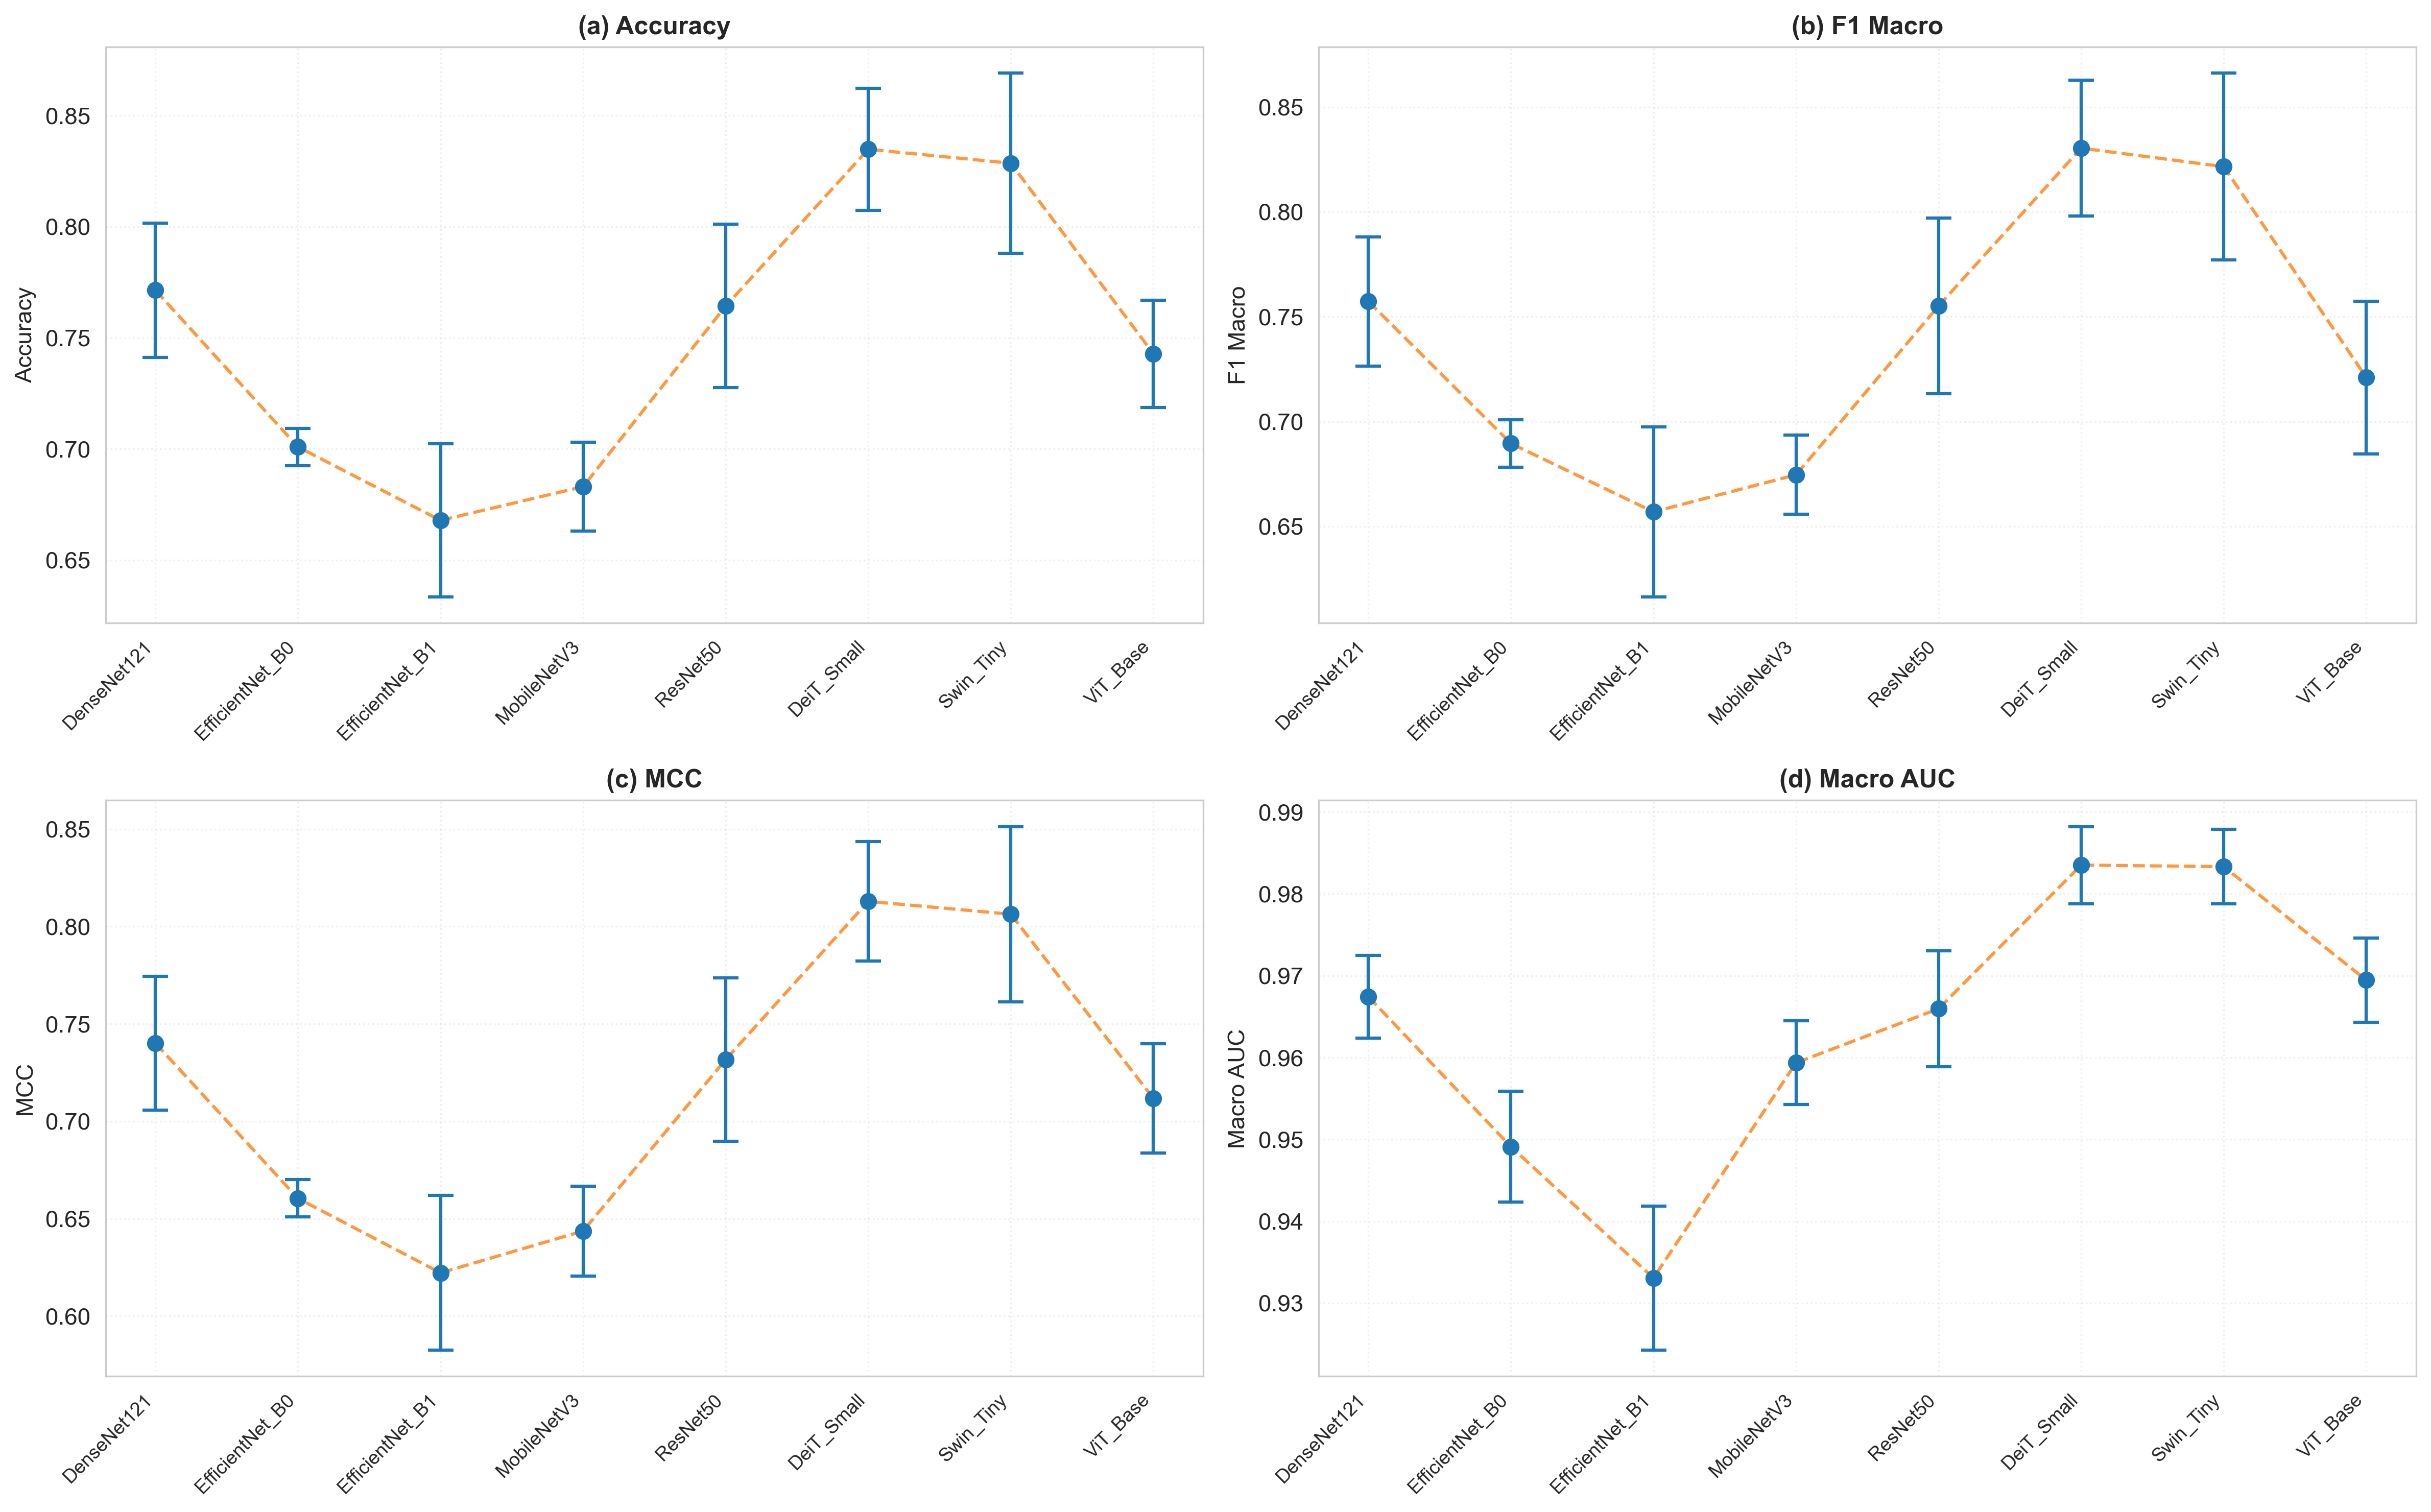


✓ Figure saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_1_Model_Performance_Mean_SD.png


In [19]:
# =============================================================================
# STEP 12-1 : OVERALL MODEL PERFORMANCE (MEAN ± SD)
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np

print("="*80)
print("STEP 12-1 : OVERALL MODEL PERFORMANCE (MEAN ± SD)")
print("="*80)

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]

titles = [
    "(a) Accuracy",
    "(b) F1 Macro",
    "(c) MCC",
    "(d) Macro AUC"
]

model_order = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50",
    "DeiT_Small",
    "Swin_Tiny",
    "ViT_Base"
]

# -------------------------------------------------------------------------
# Figure
# -------------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16,10),
    dpi=300
)

axes = axes.flatten()

for ax, metric, title in zip(axes, metrics, titles):

    means = []
    stds = []

    for model in model_order:

        values = master_df.loc[
            master_df["Model"] == model,
            metric
        ]

        means.append(values.mean())
        stds.append(values.std())

    x = np.arange(len(model_order))

    # Mean ± SD error bars
    ax.errorbar(
        x,
        means,
        yerr=stds,
        fmt='o',
        capsize=6,
        capthick=1.5,
        elinewidth=1.5,
        markersize=7,
        linestyle='None',      # don't connect points here
        zorder=3
    )
    
    # Dotted line connecting means
    ax.plot(
        x,
        means,
        linestyle='--',         # dotted/dashed line
        linewidth=1.5,
        marker=None,
        alpha=0.8,
        zorder=2
    )
    ax.set_xticks(x)

    ax.set_xticklabels(
        model_order,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_ylabel(metric)

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.grid(
        linestyle=":",
        alpha=0.3
    )

plt.tight_layout()

# -------------------------------------------------------------------------
# Save
# -------------------------------------------------------------------------

figure_path = FIGURES_DIR / "Figure_1_Model_Performance_Mean_SD.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Figure saved successfully")
print(figure_path)

STEP 12-2 : RADAR CHART OF MODEL PERFORMANCE


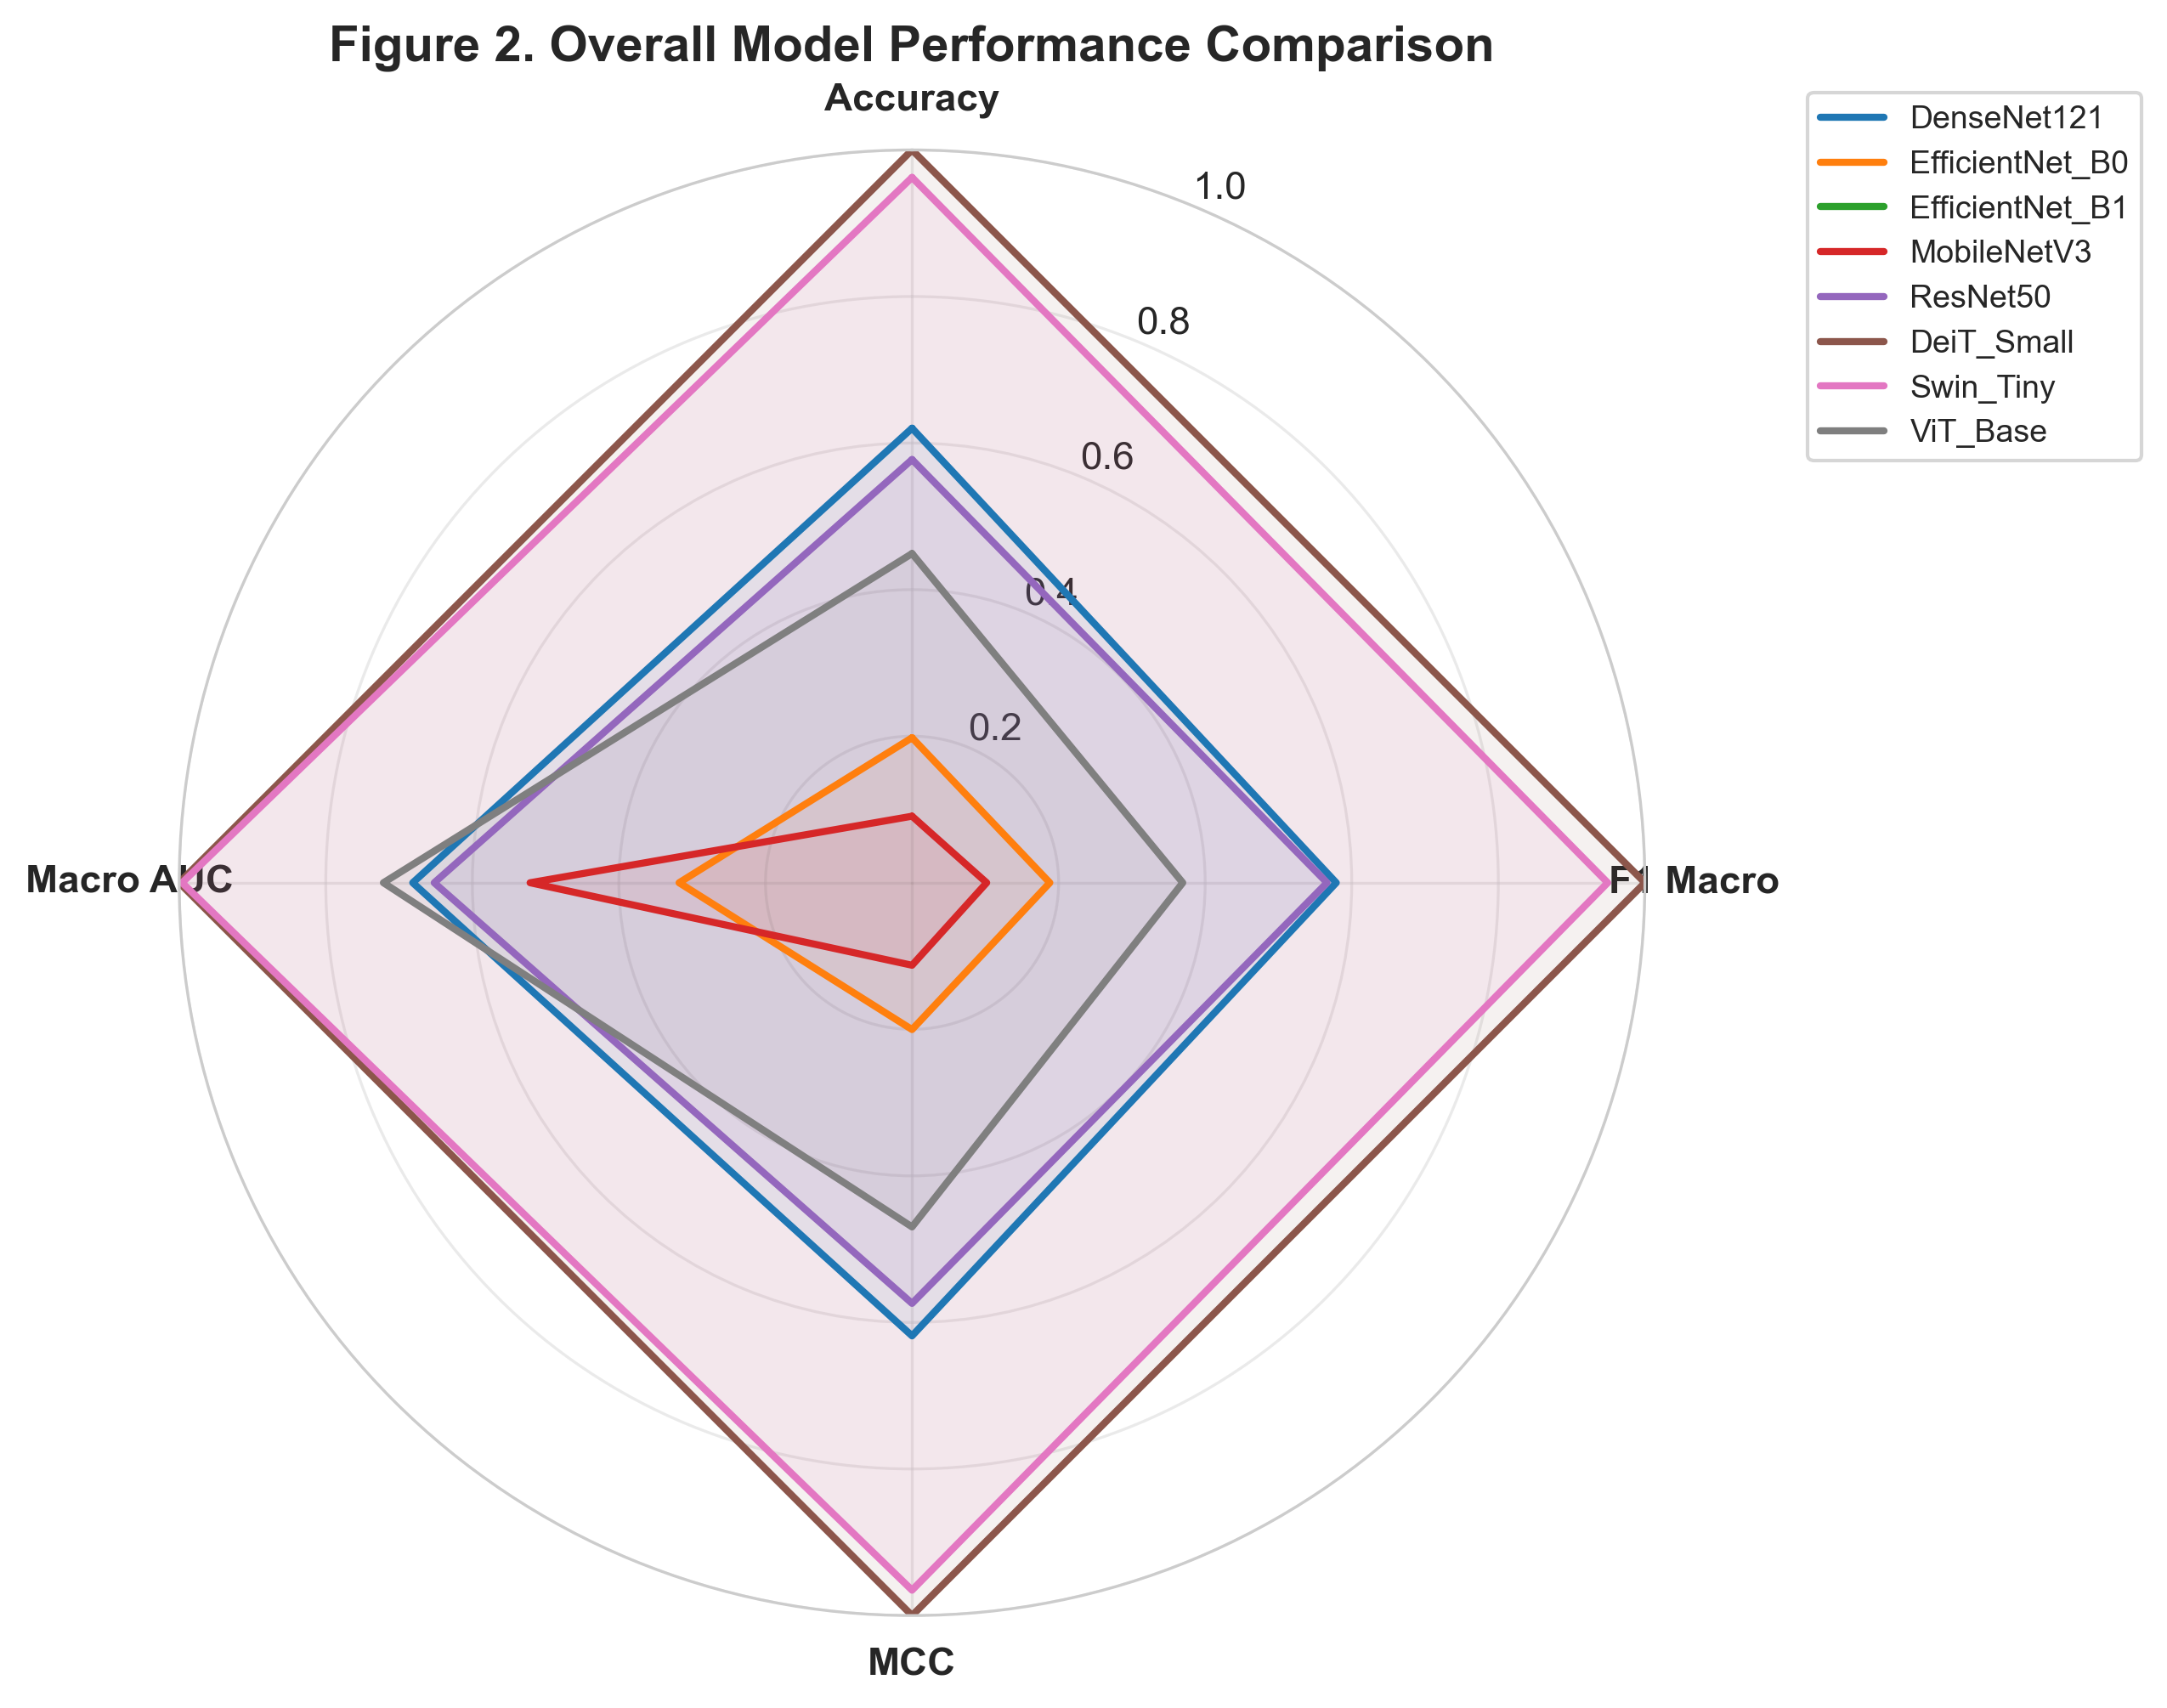


✓ Figure saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_2_Radar_Chart.png


In [20]:
import numpy as np
import matplotlib.pyplot as plt

print("="*80)
print("STEP 12-2 : RADAR CHART OF MODEL PERFORMANCE")
print("="*80)

# -------------------------------------------------------------------------
# Metrics
# -------------------------------------------------------------------------

metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]

# -------------------------------------------------------------------------
# Model Order
# -------------------------------------------------------------------------

model_order = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50",
    "DeiT_Small",
    "Swin_Tiny",
    "ViT_Base"
]

# -------------------------------------------------------------------------
# Mean values
# -------------------------------------------------------------------------

summary = (
    master_df
    .groupby("Model")[metrics]
    .mean()
    .loc[model_order]
)

# -------------------------------------------------------------------------
# Normalize each metric (0–1)
# -------------------------------------------------------------------------

summary_norm = summary.copy()

for col in metrics:

    minimum = summary[col].min()
    maximum = summary[col].max()

    summary_norm[col] = (
        (summary[col] - minimum) /
        (maximum - minimum)
    )

# -------------------------------------------------------------------------
# Radar Chart
# -------------------------------------------------------------------------

labels = summary_norm.columns.tolist()

num_vars = len(labels)

angles = np.linspace(
    0,
    2*np.pi,
    num_vars,
    endpoint=False
).tolist()

angles += angles[:1]

fig = plt.figure(figsize=(9,9), dpi=300)

ax = plt.subplot(111, polar=True)

for model in model_order:

    values = summary_norm.loc[model].tolist()

    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=model
    )

    ax.fill(
        angles,
        values,
        alpha=0.08
    )

# -------------------------------------------------------------------------
# Formatting
# -------------------------------------------------------------------------

ax.set_theta_offset(np.pi/2)
ax.set_theta_direction(-1)

ax.set_xticks(angles[:-1])

ax.set_xticklabels(
    labels,
    fontsize=11,
    fontweight="bold"
)

ax.set_ylim(0,1)

ax.set_title(
    "Figure 2. Overall Model Performance Comparison",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.grid(alpha=0.4)

plt.legend(
    bbox_to_anchor=(1.35,1.05),
    fontsize=9
)

plt.tight_layout()

# -------------------------------------------------------------------------
# Save
# -------------------------------------------------------------------------

figure_path = FIGURES_DIR / "Figure_2_Radar_Chart.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Figure saved successfully")

print(figure_path)

STEP 12-3 : COMPUTATIONAL EFFICIENCY ANALYSIS


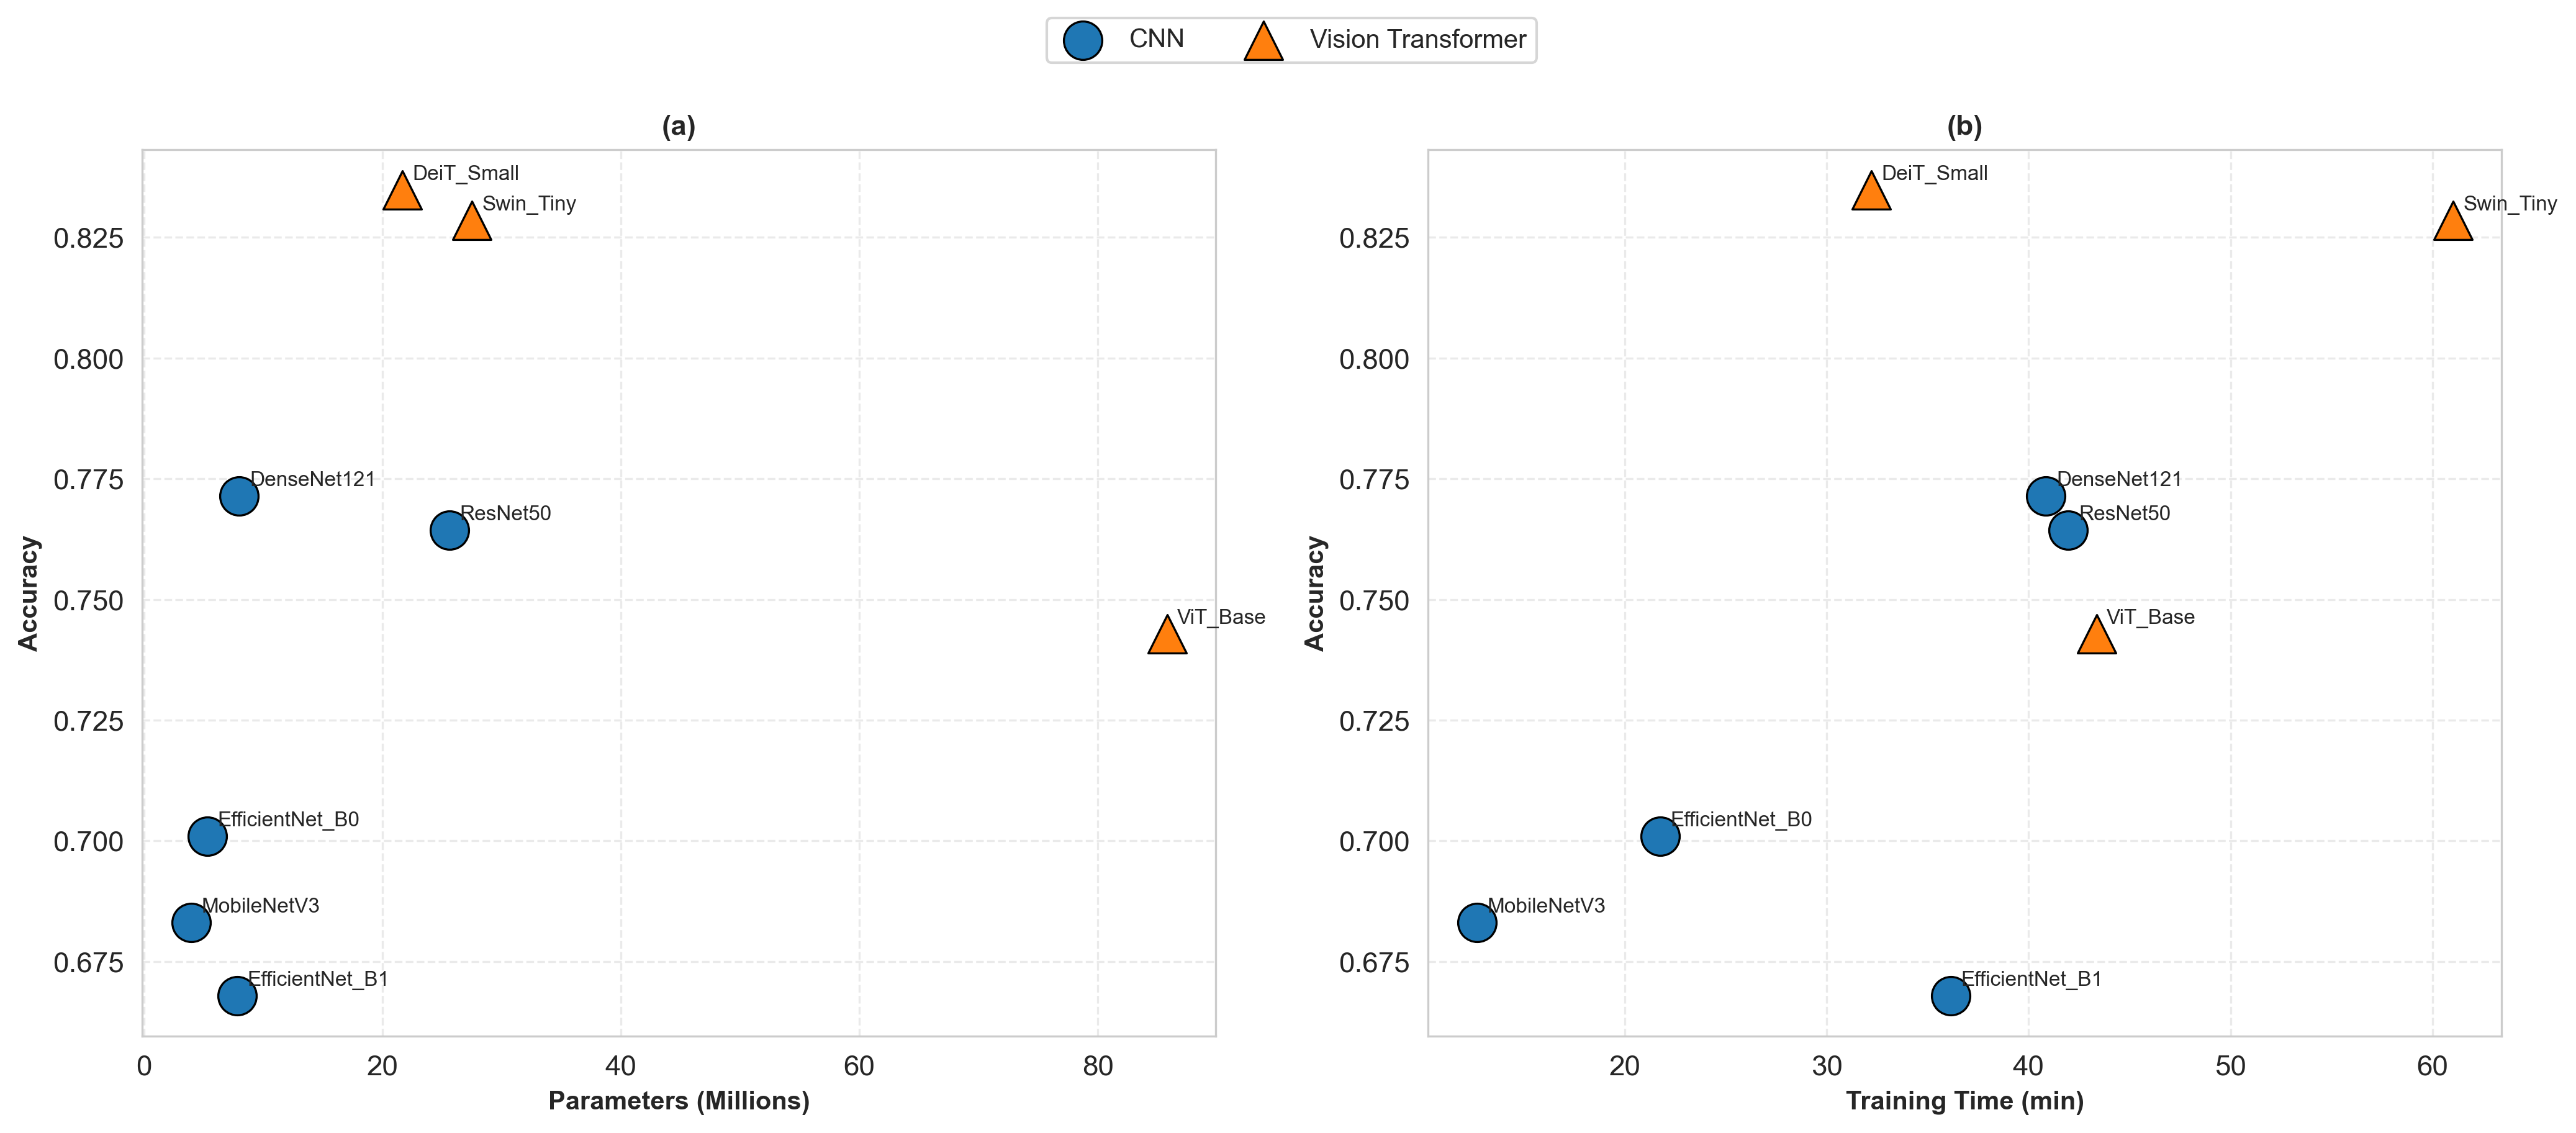


✓ Figure saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_S3_Computational_Efficiency.png


In [21]:
import matplotlib.pyplot as plt

print("="*80)
print("STEP 12-3 : COMPUTATIONAL EFFICIENCY ANALYSIS")
print("="*80)

# =============================================================================
# Summary Statistics
# =============================================================================

summary = (
    master_df
    .groupby("Model")
    .agg({
        "Accuracy": "mean",
        "Parameters": "mean",
        "Training Time (min)": "mean"
    })
    .reset_index()
)

# =============================================================================
# Model Order
# =============================================================================

model_order = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50",
    "DeiT_Small",
    "Swin_Tiny",
    "ViT_Base"
]

summary = (
    summary
    .set_index("Model")
    .loc[model_order]
    .reset_index()
)

# =============================================================================
# Model Families
# =============================================================================

cnn_models = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50"
]

vit_models = [
    "DeiT_Small",
    "Swin_Tiny",
    "ViT_Base"
]

cnn = summary[summary["Model"].isin(cnn_models)]
vit = summary[summary["Model"].isin(vit_models)]

# =============================================================================
# Create Figure
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14,6),
    dpi=300
)

# =============================================================================
# (a) Accuracy vs Model Complexity
# =============================================================================

axes[0].scatter(
    cnn["Parameters"]/1e6,
    cnn["Accuracy"],
    s=220,
    color="tab:blue",
    marker="o",
    edgecolors="black",
    linewidth=0.8,
    label="CNN"
)

axes[0].scatter(
    vit["Parameters"]/1e6,
    vit["Accuracy"],
    s=220,
    color="tab:orange",
    marker="^",
    edgecolors="black",
    linewidth=0.8,
    label="Vision Transformer"
)

for _, row in summary.iterrows():

    axes[0].annotate(
        row["Model"],
        (
            row["Parameters"]/1e6,
            row["Accuracy"]
        ),
        xytext=(4,4),
        textcoords="offset points",
        fontsize=8
    )

axes[0].set_xlabel(
    "Parameters (Millions)",
    fontsize=10,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Accuracy",
    fontsize=10,
    fontweight="bold"
)

axes[0].set_title(
    "(a)",
    fontsize=11,
    fontweight="bold"
)

axes[0].grid(
    linestyle="--",
    alpha=0.4
)

# =============================================================================
# (b) Accuracy vs Training Time
# =============================================================================

axes[1].scatter(
    cnn["Training Time (min)"],
    cnn["Accuracy"],
    s=220,
    color="tab:blue",
    marker="o",
    edgecolors="black",
    linewidth=0.8,
    label="CNN"
)

axes[1].scatter(
    vit["Training Time (min)"],
    vit["Accuracy"],
    s=220,
    color="tab:orange",
    marker="^",
    edgecolors="black",
    linewidth=0.8,
    label="Vision Transformer"
)

for _, row in summary.iterrows():

    axes[1].annotate(
        row["Model"],
        (
            row["Training Time (min)"],
            row["Accuracy"]
        ),
        xytext=(4,4),
        textcoords="offset points",
        fontsize=8
    )

axes[1].set_xlabel(
    "Training Time (min)",
    fontsize=10,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Accuracy",
    fontsize=10,
    fontweight="bold"
)

axes[1].set_title(
    "(b)",
    fontsize=11,
    fontweight="bold"
)

axes[1].grid(
    linestyle="--",
    alpha=0.4
)

# =============================================================================
# Shared Legend
# =============================================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=True,
    fontsize=10,
    bbox_to_anchor=(0.5,1.02)
)

# =============================================================================
# Layout
# =============================================================================

plt.tight_layout(rect=[0,0,1,0.95])

# =============================================================================
# Save Figure
# =============================================================================

figure_path = (
    FIGURES_DIR /
    "Figure_S3_Computational_Efficiency.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Figure saved successfully")
print(figure_path)

STEP 12-4 : MODEL RANKING HEATMAP
                 Accuracy  F1 Macro  MCC  Macro AUC  Average Rank
Model                                                            
DeiT_Small            1.0       1.0  1.0        1.0          1.00
Swin_Tiny             2.0       2.0  2.0        2.0          2.00
DenseNet121           3.0       3.0  3.0        4.0          3.25
ResNet50              4.0       4.0  4.0        5.0          4.25
ViT_Base              5.0       5.0  5.0        3.0          4.50
EfficientNet_B0       6.0       6.0  6.0        7.0          6.25
MobileNetV3           7.0       7.0  7.0        6.0          6.75
EfficientNet_B1       8.0       8.0  8.0        8.0          8.00


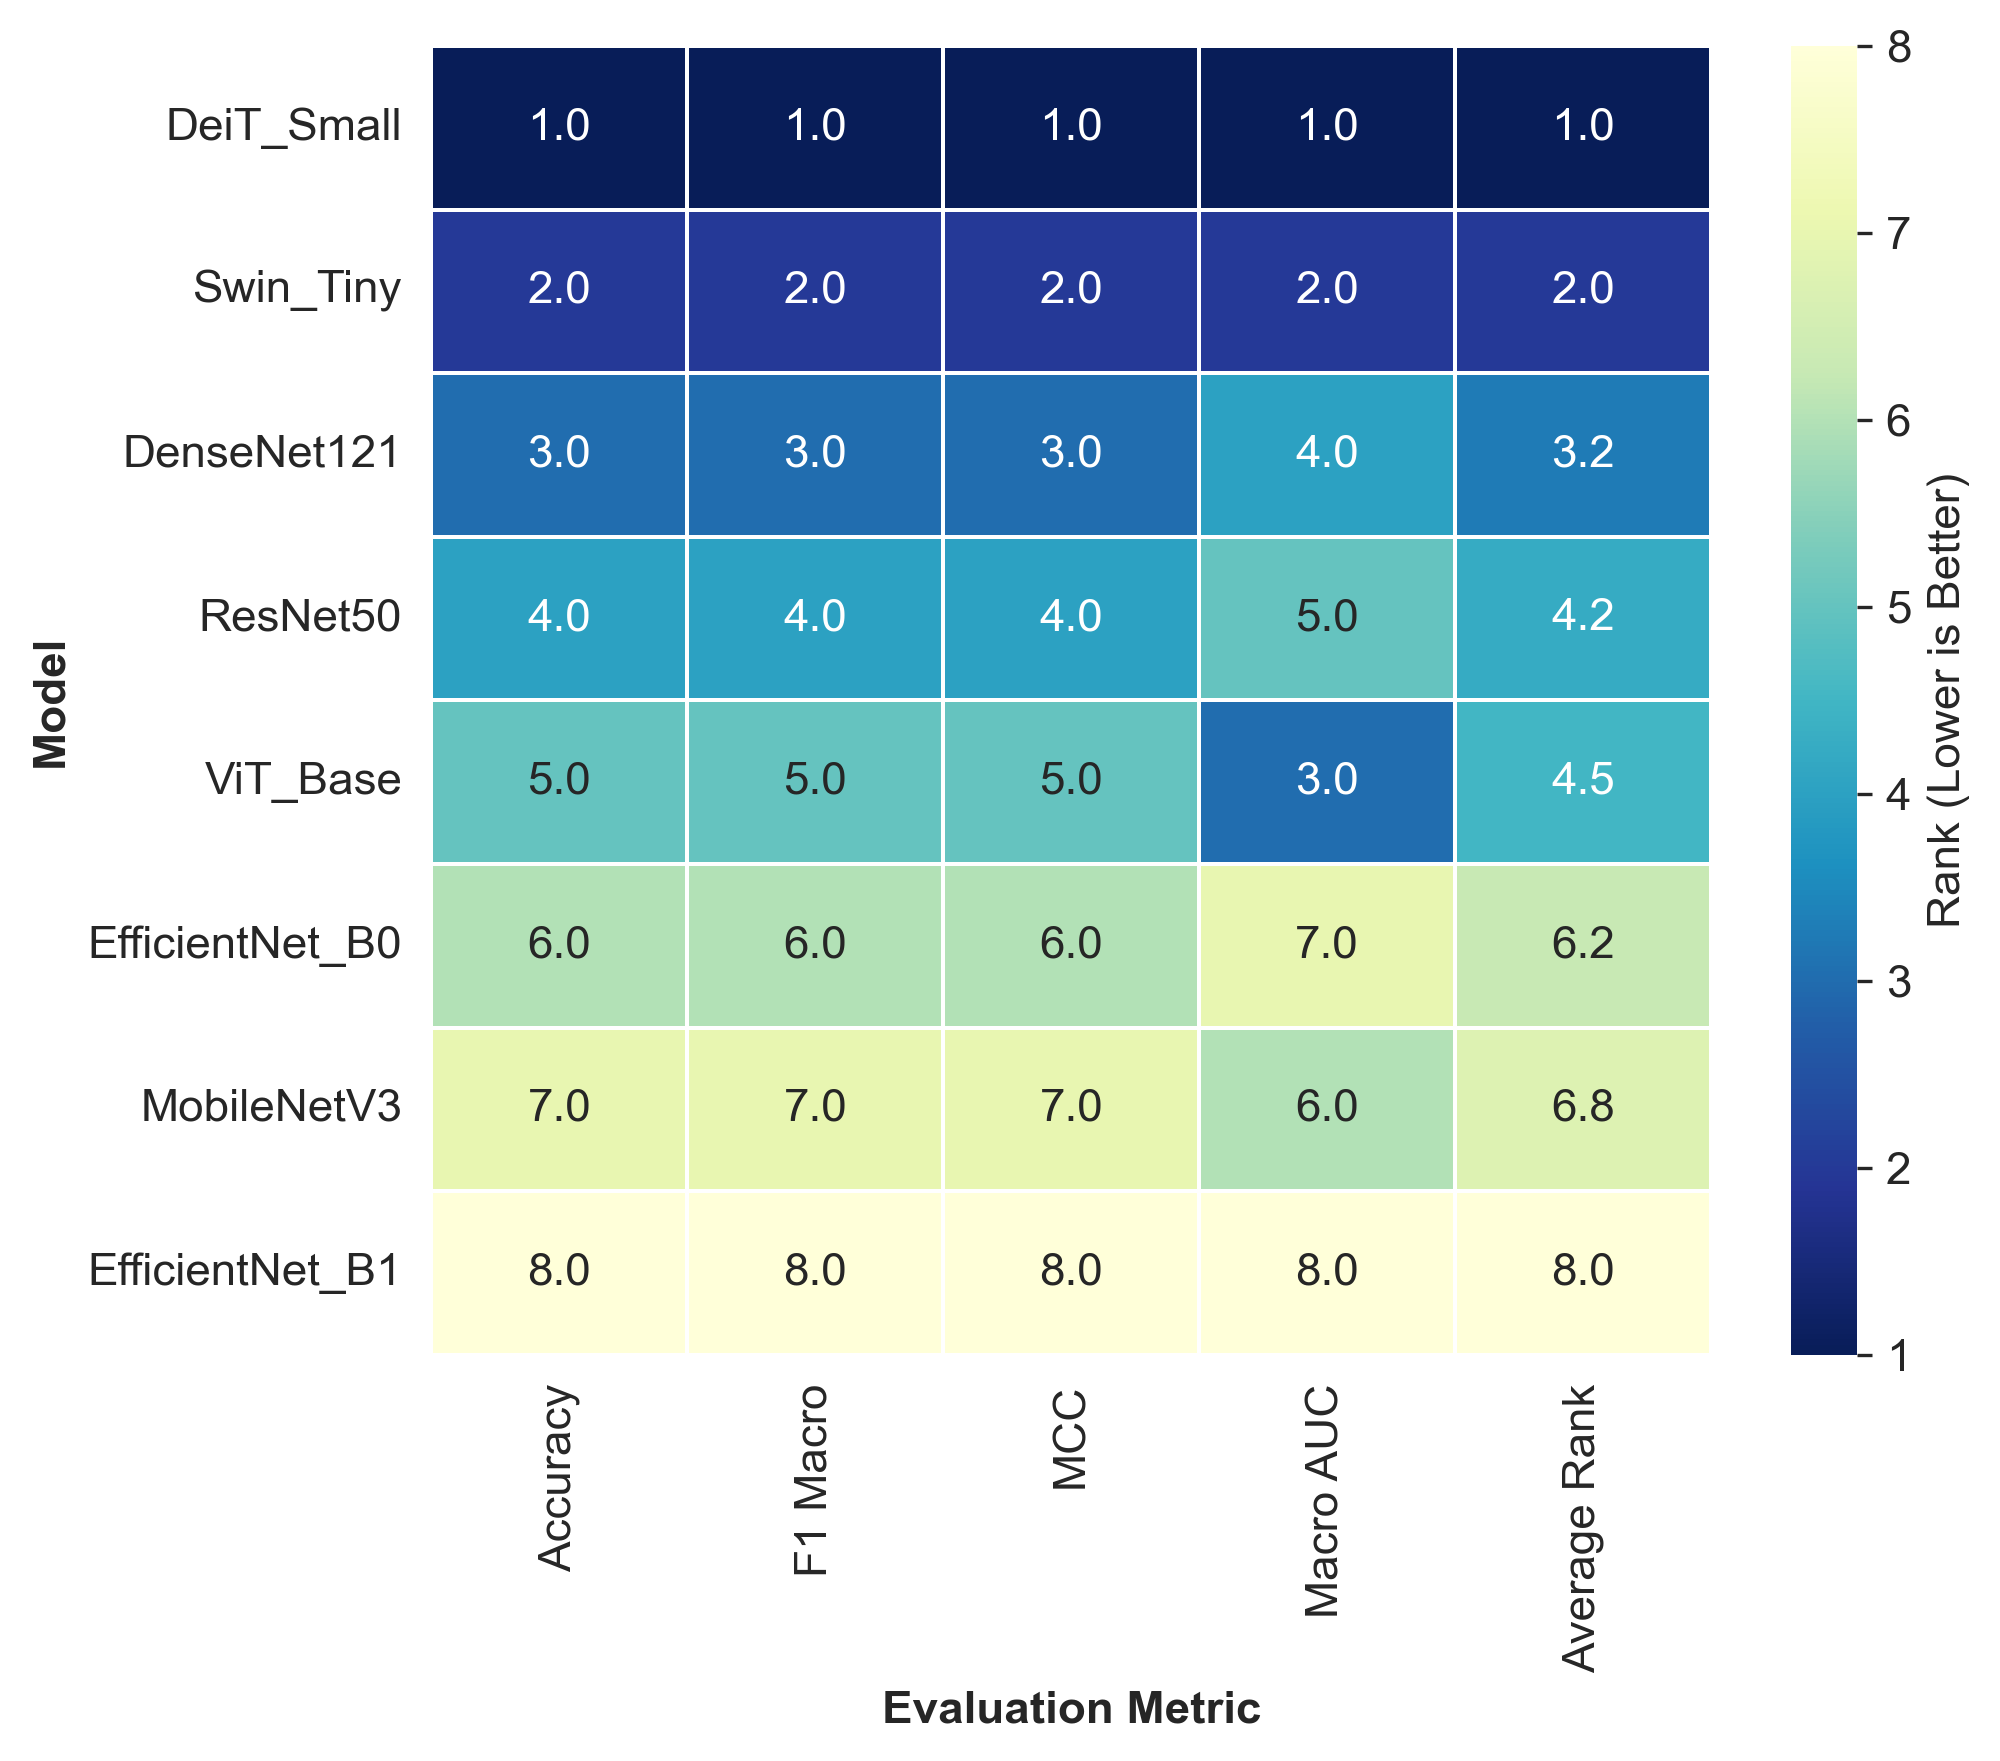


✓ Figure saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_4_Model_Ranking_Heatmap.png


In [22]:
# STEP 12-4 : MODEL RANKING HEATMAP"
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("="*80)
print("STEP 12-4 : MODEL RANKING HEATMAP")
print("="*80)

# =============================================================================
# Compute Mean Metrics
# =============================================================================

ranking_df = (
    master_df
    .groupby("Model")
    .agg({
        "Accuracy":"mean",
        "F1 Macro":"mean",
        "MCC":"mean",
        "Macro AUC":"mean"
    })
)

# =============================================================================
# Rank Each Metric (Higher is Better)
# =============================================================================

rank_df = ranking_df.rank(
    ascending=False,
    method="min"
)

rank_df["Average Rank"] = rank_df.mean(axis=1)

rank_df = rank_df.sort_values("Average Rank")

# =============================================================================
# Save Ranking Table
# =============================================================================

rank_table = rank_df.round(2)

rank_table.to_csv(
    TABLES_DIR / "Table_7_Model_Ranking.csv"
)

print(rank_table)

# =============================================================================
# Plot Heatmap
# =============================================================================

plt.figure(figsize=(7,6), dpi=300)

sns.heatmap(
    rank_df,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu_r",
    linewidths=0.5,
    cbar_kws={
        "label":"Rank (Lower is Better)"
    }
)

# plt.title(
#     "",
#     fontsize=13,
#     fontweight="bold"
# )

plt.ylabel(
    "Model",
    fontsize=11,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()

# =============================================================================
# Save
# =============================================================================

figure_path = (
    FIGURES_DIR /
    "Figure_4_Model_Ranking_Heatmap.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Figure saved successfully")
print(figure_path)

STEP 12-5 : CORRELATION HEATMAP


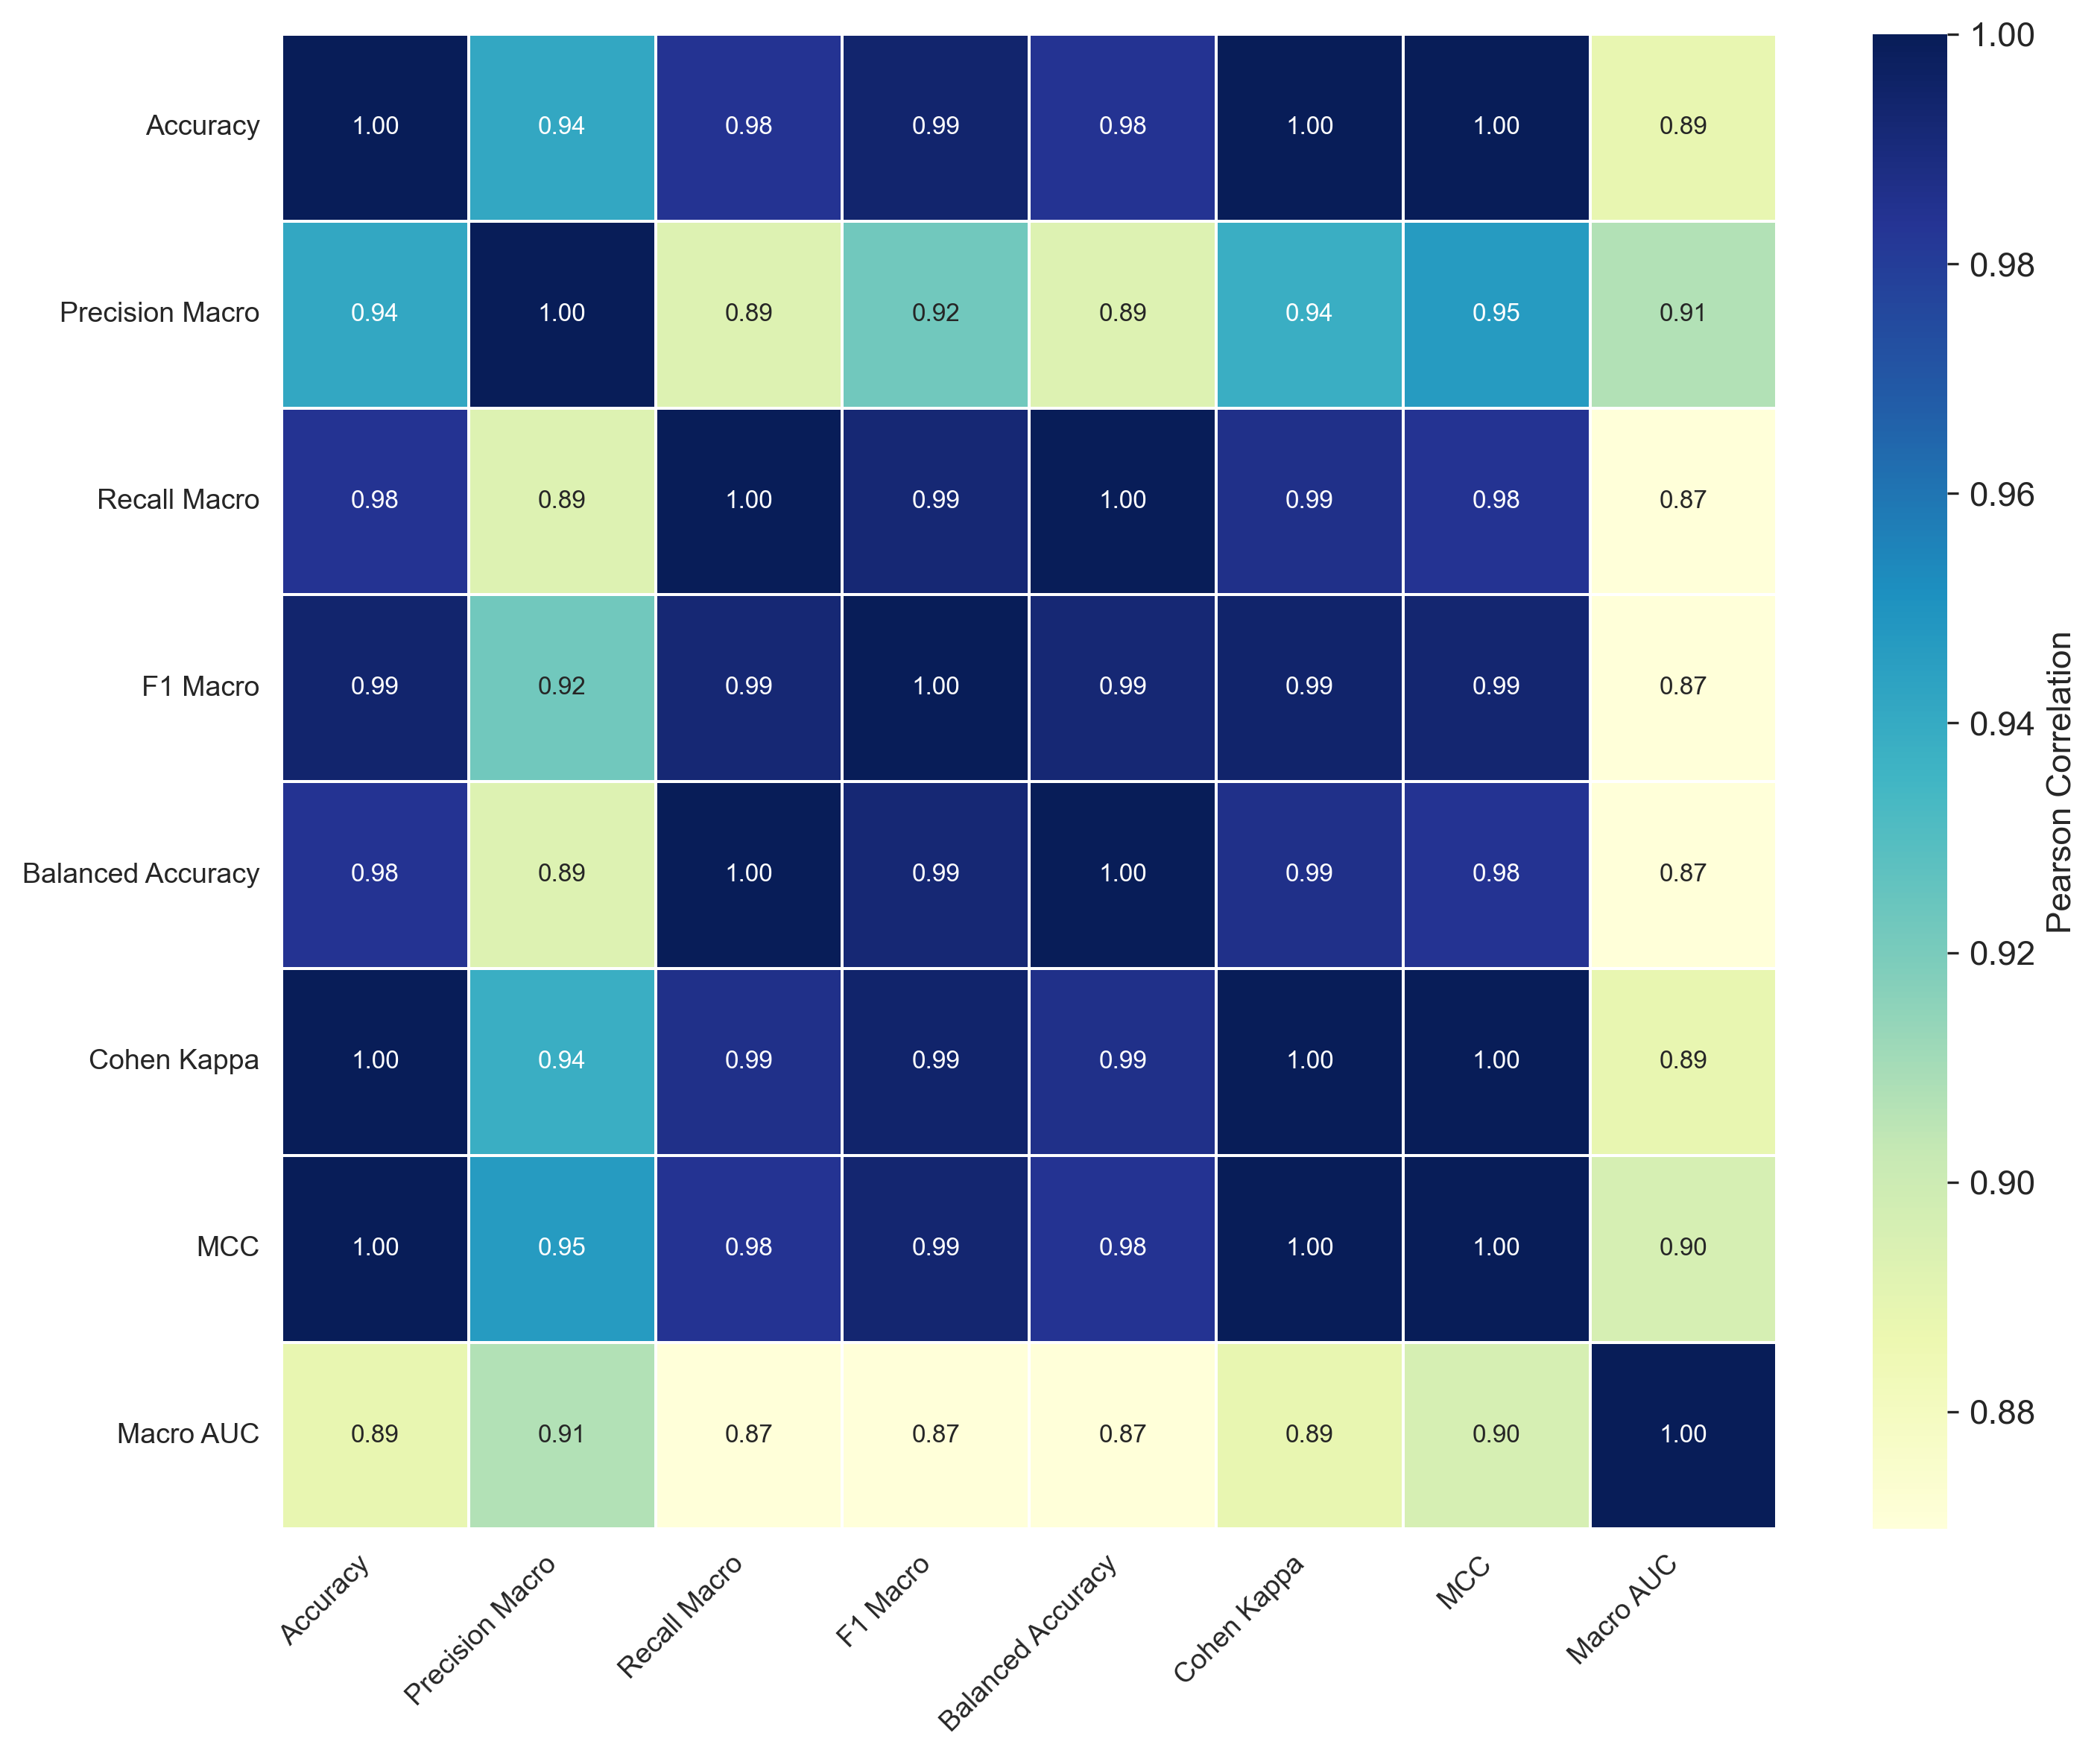


✓ Correlation matrix saved
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_S1_Correlation_Matrix.csv

✓ Figure saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_S3_Correlation_Heatmap.png


In [23]:
# Step 12- 5 : CORRELATION HEATMAP
import matplotlib.pyplot as plt
import seaborn as sns

print("="*80)
print("STEP 12-5 : CORRELATION HEATMAP")
print("="*80)

# =============================================================================
# Metrics for Correlation Analysis
# =============================================================================

metrics = [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro",
    "Balanced Accuracy",
    "Cohen Kappa",
    "MCC",
    "Macro AUC"
]

corr_df = master_df[metrics]

# =============================================================================
# Correlation Matrix
# =============================================================================

corr_matrix = corr_df.corr(method="pearson")

# Save correlation matrix
corr_matrix.to_csv(
    TABLES_DIR / "Table_S1_Correlation_Matrix.csv"
)

# =============================================================================
# Plot Heatmap
# =============================================================================

plt.figure(figsize=(10, 8), dpi=300)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson Correlation"
    },
    annot_kws={
        "size": 8
    }
)

# plt.title(
#     "Figure S3. Pearson Correlation Among Performance Metrics",
#     fontsize=13,
#     fontweight="bold"
# )

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()

# =============================================================================
# Save Figure
# =============================================================================

figure_path = (
    FIGURES_DIR /
    "Figure_S3_Correlation_Heatmap.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Correlation matrix saved")
print(TABLES_DIR / "Table_S1_Correlation_Matrix.csv")

print("\n✓ Figure saved successfully")
print(figure_path)

STEP 12-6 : PERFORMANCE VS COMPUTATIONAL COST


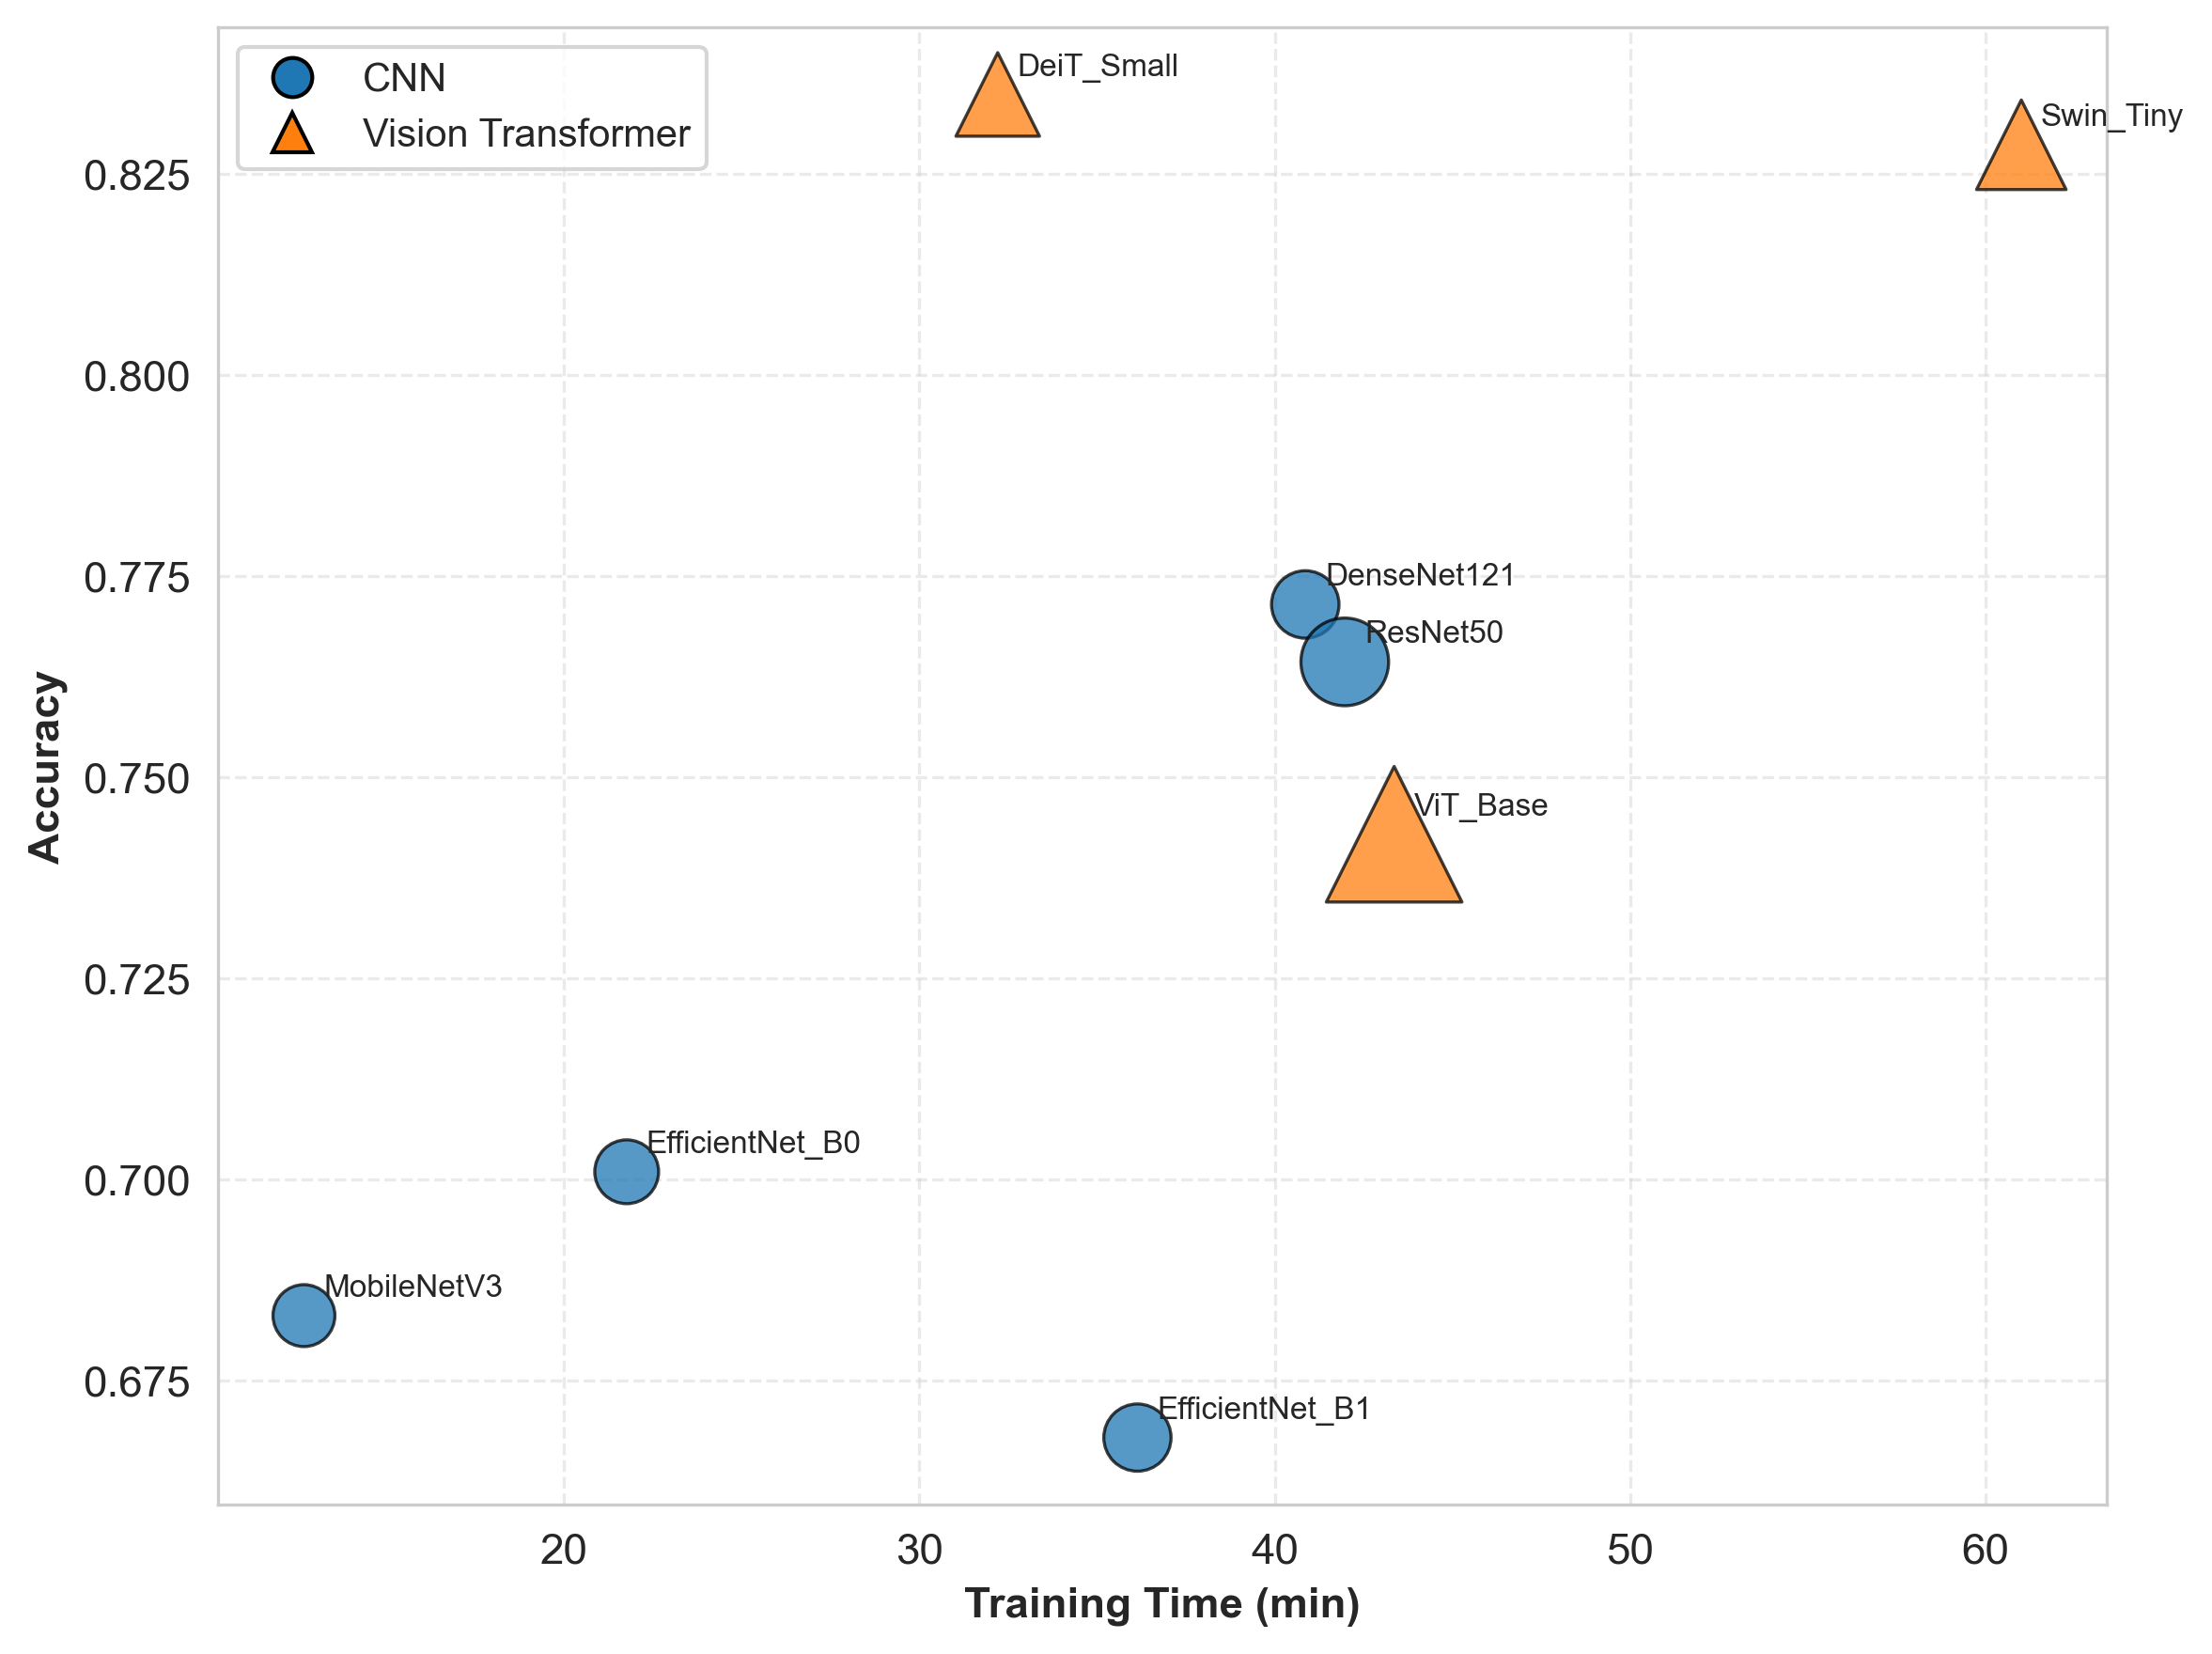


✓ Figure saved successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_S4_Performance_vs_Computational_Cost.png


In [24]:
# STEP 12-6 : PERFORMANCE VS COMPUTATIONAL COST (Bubble Plot)
import matplotlib.pyplot as plt

print("="*80)
print("STEP 12-6 : PERFORMANCE VS COMPUTATIONAL COST")
print("="*80)

# =============================================================================
# Summary Statistics
# =============================================================================

summary = (
    master_df
    .groupby("Model")
    .agg({
        "Accuracy":"mean",
        "Training Time (min)":"mean",
        "Parameters":"mean"
    })
    .reset_index()
)

cnn_models = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50"
]

vit_models = [
    "DeiT_Small",
    "Swin_Tiny",
    "ViT_Base"
]

summary["Family"] = summary["Model"].apply(
    lambda x: "CNN" if x in cnn_models else "Vision Transformer"
)

# =============================================================================
# =============================================================================
# Bubble Size (Normalized)
# =============================================================================

min_size = 250      # Smallest bubble
max_size = 1200     # Largest bubble

param_min = summary["Parameters"].min()
param_max = summary["Parameters"].max()

summary["Bubble Size"] = (
    min_size +
    (summary["Parameters"] - param_min) /
    (param_max - param_min) *
    (max_size - min_size)
)
# =============================================================================
# Plot
# =============================================================================

plt.figure(figsize=(8,6), dpi=300)

for family, marker, color in zip(
    ["CNN", "Vision Transformer"],
    ["o", "^"],
    ["tab:blue", "tab:orange"]
):

    temp = summary[summary["Family"] == family]

    plt.scatter(
        temp["Training Time (min)"],
        temp["Accuracy"],
        s=temp["Bubble Size"],
        marker=marker,
        color=color,
        edgecolors="black",
        linewidth=0.8,
        alpha=0.75,
        label=family
    )

    for _, row in temp.iterrows():

        plt.annotate(
            row["Model"],
            (
                row["Training Time (min)"],
                row["Accuracy"]
            ),
            xytext=(5,5),
            textcoords="offset points",
            fontsize=8
        )

plt.xlabel(
    "Training Time (min)",
    fontsize=11,
    fontweight="bold"
)

plt.ylabel(
    "Accuracy",
    fontsize=11,
    fontweight="bold"
)

# plt.title(
#     "Performance vs Computational Cost",
#     fontsize=12,
#     fontweight="bold"
# )

plt.grid(
    linestyle="--",
    alpha=0.4
)

from matplotlib.lines import Line2D

legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='CNN',
        markerfacecolor='tab:blue',
        markeredgecolor='black',
        markersize=10
    ),
    Line2D(
        [0], [0],
        marker='^',
        color='w',
        label='Vision Transformer',
        markerfacecolor='tab:orange',
        markeredgecolor='black',
        markersize=10
    )
]

plt.legend(
    handles=legend_elements,
    fontsize=10,
    frameon=True,
    loc="upper left"
)

plt.tight_layout()

# =============================================================================
# Save
# =============================================================================

figure_path = (
    FIGURES_DIR /
    "Figure_S4_Performance_vs_Computational_Cost.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Figure saved successfully")
print(figure_path)

In [27]:
# ============================================================
# STEP 13 : MOST FREQUENTLY MISCLASSIFIED IMAGES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 80)
print("STEP 13 : MOST FREQUENTLY MISCLASSIFIED IMAGES")
print("=" * 80)

# ----------------------------------------------------------
# Prediction folders defined in STEP 1
# ----------------------------------------------------------

CNN_DIR = CNN_PREDICTIONS_DIR
VIT_DIR = VIT_PREDICTIONS_DIR

# ----------------------------------------------------------
# Validate prediction directories
# ----------------------------------------------------------

if not CNN_DIR.exists():
    raise FileNotFoundError(
        f"CNN prediction directory not found:\n{CNN_DIR}"
    )

if not VIT_DIR.exists():
    raise FileNotFoundError(
        f"Vision Transformer prediction directory not found:\n{VIT_DIR}"
    )

print(f"CNN prediction directory : {CNN_DIR}")
print(f"ViT prediction directory : {VIT_DIR}")

# ----------------------------------------------------------
# Read prediction tables
# ----------------------------------------------------------

prediction_files = (
    list(CNN_DIR.glob("*Prediction_Table.csv"))
    + list(VIT_DIR.glob("*Prediction_Table.csv"))
)

print(f"\nPrediction files found : {len(prediction_files)}")

if not prediction_files:
    raise FileNotFoundError(
        "No *_Prediction_Table.csv files were found "
        "in the CNN or Vision Transformer prediction directories."
    )

dfs = []

for f in prediction_files:

    print(f"Reading: {f.name}")

    df = pd.read_csv(f)

    # ------------------------------------------------------
    # Basic validation
    # ------------------------------------------------------

    required_columns = [
        "Image_Name",
        "True_Class",
        "Predicted_Class",
        "Correct",
        "Prediction_Probability",
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"\nMissing columns in prediction file:\n"
            f"{f}\n"
            f"Missing: {missing_columns}"
        )

    # ------------------------------------------------------
    # Add image path if not already present
    # ------------------------------------------------------

    if "Image_Path" not in df.columns:
        df["Image_Path"] = ""

    dfs.append(df)

# ----------------------------------------------------------
# Combine all prediction tables
# ----------------------------------------------------------

master_predictions = pd.concat(
    dfs,
    ignore_index=True
)

print(
    f"\nTotal prediction records : "
    f"{len(master_predictions):,}"
)

# ----------------------------------------------------------
# Standardize Correct column
# ----------------------------------------------------------

if master_predictions["Correct"].dtype == object:

    master_predictions["Correct"] = (
        master_predictions["Correct"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
            "yes": True,
            "no": False
        })
    )

master_predictions["Correct"] = (
    master_predictions["Correct"]
    .fillna(False)
    .astype(bool)
)

# ----------------------------------------------------------
# CNN vs Vision Transformer
# ----------------------------------------------------------

cnn_models = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50",
]

master_predictions["Architecture"] = np.where(
    master_predictions["Model"].isin(cnn_models),
    "CNN",
    "Vision Transformer"
)

# ----------------------------------------------------------
# Error statistics for every image
# ----------------------------------------------------------

rows = []

for (img, true_class), grp in master_predictions.groupby(
    ["Image_Name", "True_Class"],
    dropna=False
):

    # ------------------------------------------------------
    # Incorrect predictions
    # ------------------------------------------------------

    wrong = grp[~grp["Correct"]]

    wrong_count = len(wrong)
    correct_count = int(grp["Correct"].sum())

    # ------------------------------------------------------
    # Most common wrong prediction
    # ------------------------------------------------------

    if wrong_count > 0:

        wrong_class_counts = (
            wrong["Predicted_Class"]
            .value_counts()
        )

        most_wrong = wrong_class_counts.idxmax()

        most_wrong_freq = int(
            wrong_class_counts.max()
        )

        mean_conf = (
            pd.to_numeric(
                wrong["Prediction_Probability"],
                errors="coerce"
            )
            .mean()
        )

    else:

        most_wrong = "-"
        most_wrong_freq = 0
        mean_conf = np.nan

    # ------------------------------------------------------
    # CNN errors
    # ------------------------------------------------------

    cnn_grp = grp[
        grp["Architecture"] == "CNN"
    ]

    cnn_wrong = int(
        (~cnn_grp["Correct"]).sum()
    )

    # ------------------------------------------------------
    # ViT errors
    # ------------------------------------------------------

    vit_grp = grp[
        grp["Architecture"] == "Vision Transformer"
    ]

    vit_wrong = int(
        (~vit_grp["Correct"]).sum()
    )

    # ------------------------------------------------------
    # Image path
    # ------------------------------------------------------

    image_path = ""

    if "Image_Path" in grp.columns:

        valid_paths = (
            grp["Image_Path"]
            .dropna()
            .astype(str)
        )

        valid_paths = valid_paths[
            valid_paths.str.strip() != ""
        ]

        if len(valid_paths) > 0:
            image_path = valid_paths.iloc[0]

    # ------------------------------------------------------
    # Append result
    # ------------------------------------------------------

    rows.append({

        "Image_Name": img,

        "Image_Path": image_path,

        "True_Class": true_class,

        "Wrong_Count": wrong_count,

        "Correct_Count": correct_count,

        "Total_Predictions": len(grp),

        "Error_%": (
            100 * wrong_count / len(grp)
            if len(grp) > 0
            else np.nan
        ),

        "Most_Common_Wrong_Class": most_wrong,

        "Wrong_Class_Frequency": most_wrong_freq,

        "CNN_Wrong": cnn_wrong,

        "ViT_Wrong": vit_wrong,

        "Mean_Wrong_Confidence": mean_conf,

    })

# ----------------------------------------------------------
# Create image-level error table
# ----------------------------------------------------------

error_df = pd.DataFrame(rows)

if error_df.empty:

    raise ValueError(
        "No image-level error statistics could be generated."
    )

# ----------------------------------------------------------
# Rank hardest image within every class
# ----------------------------------------------------------

hardest_df = (
    error_df
    .sort_values(
        [
            "True_Class",
            "Wrong_Count",
            "Mean_Wrong_Confidence",
        ],
        ascending=[
            True,
            False,
            False,
        ],
        na_position="last",
    )
    .groupby(
        "True_Class",
        group_keys=False
    )
    .head(1)
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# Add rank
# ----------------------------------------------------------

hardest_df.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(hardest_df) + 1
    )
)

# ----------------------------------------------------------
# Save tables
# ----------------------------------------------------------

error_file = (
    TABLES_DIR
    / "Table_S3_All_Image_Error_Statistics.csv"
)

hardest_file = (
    TABLES_DIR
    / "Table_9_Hardest_Images_By_Class.csv"
)

error_df.to_csv(
    error_file,
    index=False
)

hardest_df.to_csv(
    hardest_file,
    index=False
)

# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("\n" + "=" * 80)
print("HARDEST IMAGE FROM EACH CLASS")
print("=" * 80)

display(hardest_df)

print("\n" + "=" * 80)
print("FILES SAVED")
print("=" * 80)

print(f"\nAll image error statistics:")
print(error_file)

print(f"\nHardest image by class:")
print(hardest_file)

print("\n✓ STEP 13 COMPLETED SUCCESSFULLY")

STEP 13 : MOST FREQUENTLY MISCLASSIFIED IMAGES
CNN prediction directory : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Predictions
ViT prediction directory : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Evaluation\Predictions

Prediction files found : 40
Reading: DenseNet121_Run1_Prediction_Table.csv
Reading: DenseNet121_Run2_Prediction_Table.csv
Reading: DenseNet121_Run3_Prediction_Table.csv
Reading: DenseNet121_Run4_Prediction_Table.csv
Reading: DenseNet121_Run5_Prediction_Table.csv
Reading: EfficientNet_B0_Run1_Prediction_Table.csv
Reading: EfficientNet_B0_Run2_Prediction_Table.csv
Reading: EfficientNet_B0_Run3_Prediction_Table.csv
Reading: EfficientNet_B0_Run4_Prediction_Table.csv
Reading: EfficientNet_B0_Run5_Prediction_Table.csv
Reading: EfficientNet_B1_Run1_Prediction_Table.csv
Reading: EfficientNet_B1_Run2_Prediction_Table.csv
Reading: Effic

,Rank,Image_Name,Image_Path,True_Class,Wrong_Count,Correct_Count,Total_Predictions,Error_%,Most_Common_Wrong_Class,Wrong_Class_Frequency,CNN_Wrong,ViT_Wrong,Mean_Wrong_Confidence
0,1,BSS102.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,BSS,38,2,40,95.0,RM,37,25,13,0.905469
1,2,CL42.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,CL,40,0,40,100.0,BSS,29,25,15,0.740203
2,3,FS41.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,FS,40,0,40,100.0,TCS,22,25,15,0.797031
3,4,HBCS21.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HBCS,27,13,40,67.5,BSS,14,21,6,0.612788
4,5,HCS23.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HCS,40,0,40,100.0,PL,33,25,15,0.882570
5,6,PCS123.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,PCS,31,9,40,77.5,TCS,30,19,12,0.721472
6,7,PL171.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,PL,35,5,40,87.5,TCS,20,24,11,0.667398
7,8,RM218.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,RM,19,21,40,47.5,TCS,7,11,8,0.504486
8,9,TC228.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,TCS,31,9,40,77.5,PL,25,18,13,0.744323



FILES SAVED

All image error statistics:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_S3_All_Image_Error_Statistics.csv

Hardest image by class:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_9_Hardest_Images_By_Class.csv

✓ STEP 13 COMPLETED SUCCESSFULLY


In [28]:
# ============================================================
# STEP 14 : PUBLICATION TABLE OF HARDEST IMAGES
# ============================================================

print("="*80)
print("STEP 14 : PUBLICATION SUMMARY OF HARDEST IMAGES")
print("="*80)

# ----------------------------------------------------------
# Build publication table
# ----------------------------------------------------------

publication_table = hardest_df.copy()

publication_table["Total Runs"] = (
    publication_table["Wrong_Count"] +
    publication_table["Correct_Count"]
)

publication_table["Accuracy"] = (
    100 * publication_table["Correct_Count"] /
    publication_table["Total Runs"]
).round(2)

publication_table["Misclassification (%)"] = (
    100 * publication_table["Wrong_Count"] /
    publication_table["Total Runs"]
).round(2)

cnn_total_predictions = int(
    (master_predictions["Architecture"] == "CNN").sum()
    / max(master_predictions["Image_Name"].nunique(), 1)
)
vit_total_predictions = int(
    (master_predictions["Architecture"] == "Vision Transformer").sum()
    / max(master_predictions["Image_Name"].nunique(), 1)
)

publication_table["CNN Error (%)"] = (
    100 * publication_table["CNN_Wrong"] /
    max(cnn_total_predictions, 1)
).round(2)

publication_table["Transformer Error (%)"] = (
    100 * publication_table["ViT_Wrong"] /
    max(vit_total_predictions, 1)
).round(2)

publication_table["Average Wrong Confidence"] = (
    publication_table["Mean_Wrong_Confidence"]
).round(3)

publication_table.rename(columns={

    "Image_Name":"Representative Image",

    "True_Class":"Sedimentary Structure",

    "Wrong_Count":"Wrong Predictions",

    "Correct_Count":"Correct Predictions",

    "Most_Common_Wrong_Class":"Dominant Misclassification",

    "Wrong_Class_Frequency":"Dominant Error Frequency"

}, inplace=True)

# ----------------------------------------------------------
# Column order
# ----------------------------------------------------------

publication_table = publication_table[[
    "Rank",
    "Sedimentary Structure",
    "Representative Image",
    "Image_Path",                 # <-- KEEP THIS
    "Wrong Predictions",
    "Correct Predictions",
    "Misclassification (%)",
    "Accuracy",
    "Dominant Misclassification",
    "Dominant Error Frequency",
    "CNN_Wrong",
    "ViT_Wrong",
    "CNN Error (%)",
    "Transformer Error (%)",
    "Average Wrong Confidence"
]]

# ----------------------------------------------------------
# Save
# ----------------------------------------------------------

table14_file = (
    TABLES_DIR /
    "Table_10_Representative_Misclassified_Images.csv"
)

publication_table.to_csv(
    table14_file,
    index=False
)

print("\nTable Saved Successfully")
print(table14_file)

display(publication_table)

STEP 14 : PUBLICATION SUMMARY OF HARDEST IMAGES

Table Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_10_Representative_Misclassified_Images.csv


,Rank,Sedimentary Structure,Representative Image,Image_Path,Wrong Predictions,Correct Predictions,Misclassification (%),Accuracy,Dominant Misclassification,Dominant Error Frequency,CNN_Wrong,ViT_Wrong,CNN Error (%),Transformer Error (%),Average Wrong Confidence
0,1,BSS,BSS102.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,38,2,95.0,5.0,RM,37,25,13,100.0,86.67,0.905
1,2,CL,CL42.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,40,0,100.0,0.0,BSS,29,25,15,100.0,100.00,0.740
2,3,FS,FS41.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,40,0,100.0,0.0,TCS,22,25,15,100.0,100.00,0.797
3,4,HBCS,HBCS21.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,27,13,67.5,32.5,BSS,14,21,6,84.0,40.00,0.613
4,5,HCS,HCS23.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,40,0,100.0,0.0,PL,33,25,15,100.0,100.00,0.883
5,6,PCS,PCS123.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,31,9,77.5,22.5,TCS,30,19,12,76.0,80.00,0.721
6,7,PL,PL171.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,35,5,87.5,12.5,TCS,20,24,11,96.0,73.33,0.667
7,8,RM,RM218.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,19,21,47.5,52.5,TCS,7,11,8,44.0,53.33,0.504
8,9,TCS,TC228.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,31,9,77.5,22.5,PL,25,18,13,72.0,86.67,0.744


STEP 15 : REPRESENTATIVE FAILURE CASES


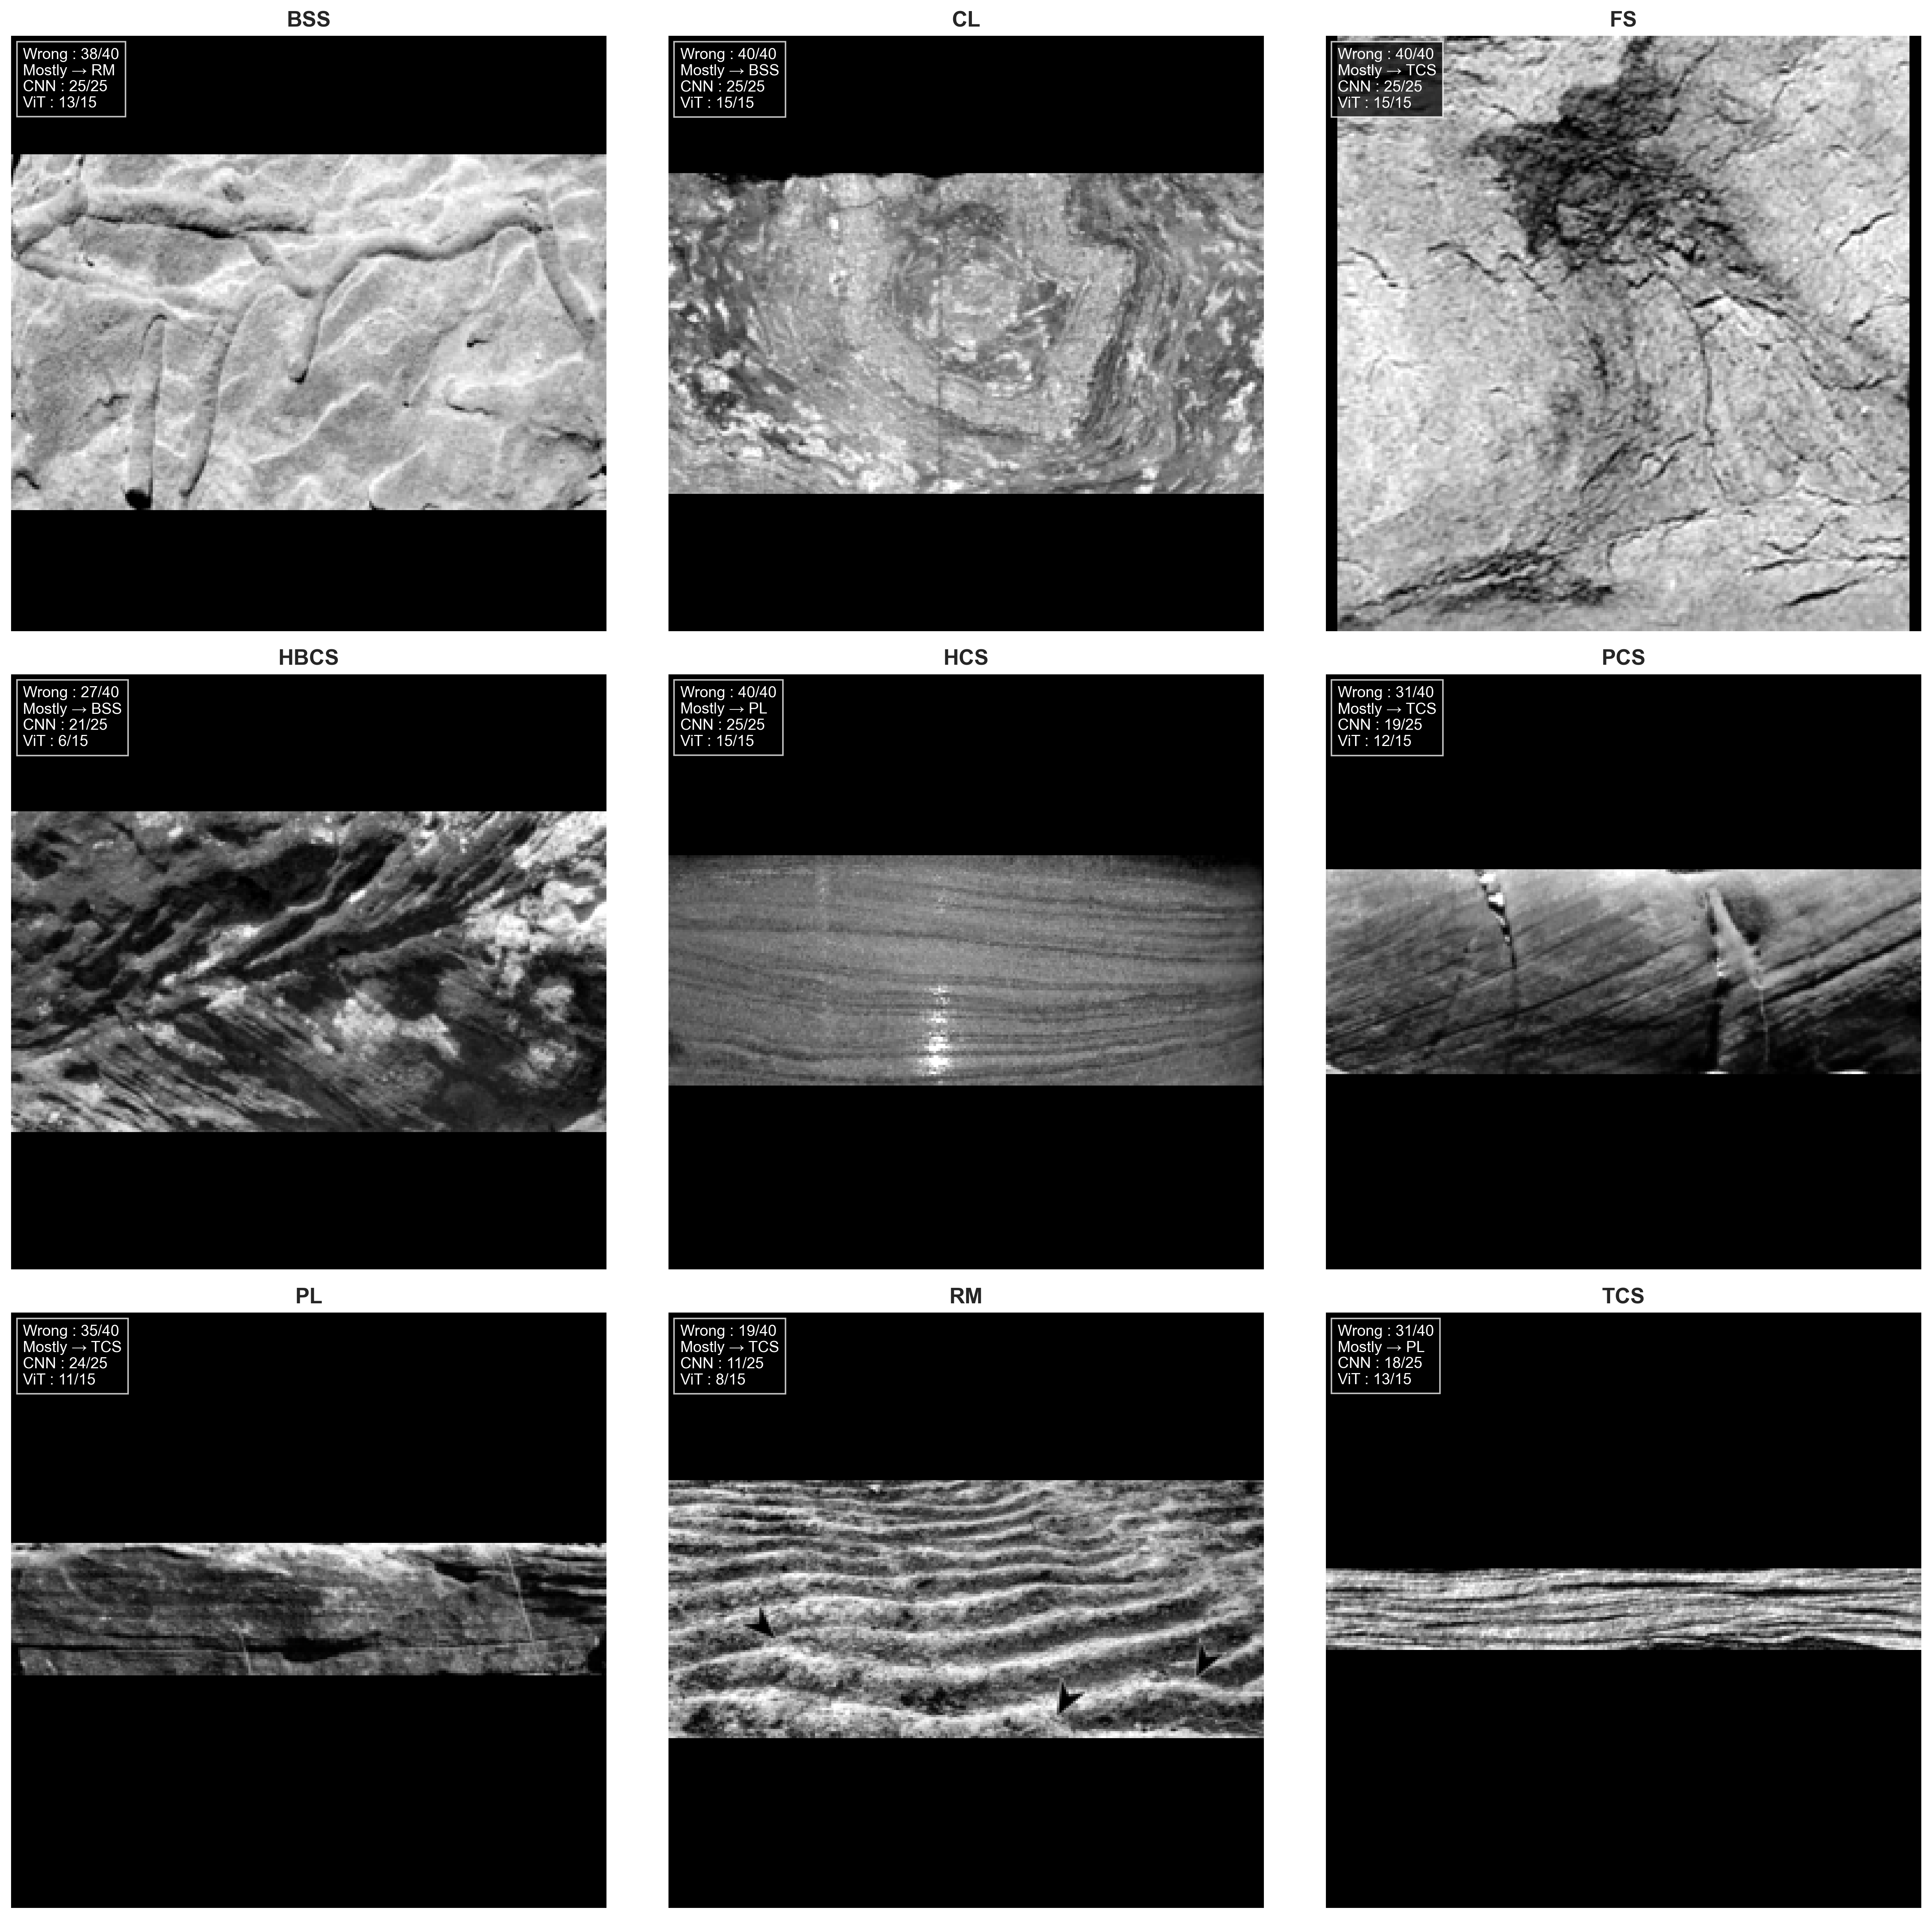


Figure Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_5_Representative_Failure_Cases.png


In [30]:
# ============================================================
# STEP 15 : REPRESENTATIVE FAILURE CASES
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

print("="*80)
print("STEP 15 : REPRESENTATIVE FAILURE CASES")
print("="*80)

# ----------------------------------------------------------
# Read Table 10
# ----------------------------------------------------------

table10 = pd.read_csv(
    TABLES_DIR /
    "Table_10_Representative_Misclassified_Images.csv"
)

# ----------------------------------------------------------
# Figure
# ----------------------------------------------------------

fig, axes = plt.subplots(
    3,
    3,
    figsize=(18,18)
)

axes = axes.flatten()

# ----------------------------------------------------------
# Loop
# ----------------------------------------------------------

for ax, (_, row) in zip(axes, table10.iterrows()):

    image_path = Path(row["Image_Path"])

    if not image_path.exists():
        ax.text(
            0.5, 0.5,
            f"Image not found:\n{image_path}",
            ha="center",
            va="center",
            wrap=True,
            fontsize=9
        )
        ax.axis("off")
        continue

    img = mpimg.imread(image_path)

    ax.imshow(img, cmap="gray", vmin=0, vmax=1)

    ax.set_title(
        row["Sedimentary Structure"],
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")

    text = (
        f"Wrong : {row['Wrong Predictions']}/{row['Wrong Predictions']+row['Correct Predictions']}\n"
        f"Mostly → {row['Dominant Misclassification']}\n"
        f"CNN : {row['CNN_Wrong']}/{cnn_total_predictions}\n"
        f"ViT : {row['ViT_Wrong']}/{vit_total_predictions}"
    )

    ax.text(
        0.02,
        0.98,
        text,
        transform=ax.transAxes,
        fontsize=10,
        color="white",
        verticalalignment="top",
        bbox=dict(
            facecolor="black",
            alpha=0.75,
            edgecolor="white"
        )
    )

# ----------------------------------------------------------
# Layout
# ----------------------------------------------------------

# plt.suptitle(
#     "Representative Failure Cases Across CNN and Vision Transformer Models",
#     fontsize=20,
#     fontweight="bold"
# )

plt.tight_layout(rect=[0,0,1,0.97])

# ----------------------------------------------------------
# Save
# ----------------------------------------------------------

figure_file = (
    FIGURES_DIR /
    "Figure_5_Representative_Failure_Cases.png"
)

plt.savefig(
    figure_file,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nFigure Saved Successfully")
print(figure_file)

In [31]:
# ============================================================
# STEP 16 : CROSS-ARCHITECTURE ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

print("="*80)
print("STEP 16 : CROSS-ARCHITECTURE ERROR ANALYSIS")
print("="*80)

# ----------------------------------------------------------
# Use master_predictions from STEP 13
# ----------------------------------------------------------

# If not available, uncomment:
# master_predictions = pd.concat(
#     [pd.read_csv(f) for f in prediction_files],
#     ignore_index=True
# )

# ----------------------------------------------------------
# CNN and Transformer Models
# ----------------------------------------------------------

cnn_models = [
    "DenseNet121",
    "EfficientNet_B0",
    "EfficientNet_B1",
    "MobileNetV3",
    "ResNet50"
]

vit_models = [
    "DeiT_Small",
    "Swin_Tiny",
    "ViT_Base"
]

master_predictions["Architecture"] = np.where(
    master_predictions["Model"].isin(cnn_models),
    "CNN",
    "Vision Transformer"
)

# ----------------------------------------------------------
# Class-wise Analysis
# ----------------------------------------------------------

rows = []

classes = sorted(master_predictions["True_Class"].unique())

for cls in classes:

    cnn = master_predictions[
        (master_predictions["Architecture"]=="CNN") &
        (master_predictions["True_Class"]==cls)
    ]

    vit = master_predictions[
        (master_predictions["Architecture"]=="Vision Transformer") &
        (master_predictions["True_Class"]==cls)
    ]

    cnn_total = len(cnn)
    vit_total = len(vit)

    cnn_correct = cnn["Correct"].sum()
    vit_correct = vit["Correct"].sum()

    cnn_wrong = cnn_total - cnn_correct
    vit_wrong = vit_total - vit_correct

    cnn_acc = 100 * cnn_correct / cnn_total
    vit_acc = 100 * vit_correct / vit_total

    cnn_error = 100 * cnn_wrong / cnn_total
    vit_error = 100 * vit_wrong / vit_total

    difference = abs(cnn_acc - vit_acc)

    if cnn_acc > vit_acc:
        better = "CNN"
    elif vit_acc > cnn_acc:
        better = "Vision Transformer"
    else:
        better = "Tie"

    rows.append({

        "Sedimentary Structure": cls,

        "CNN Accuracy": round(cnn_acc,2),

        "ViT Accuracy": round(vit_acc,2),

        "CNN Error (%)": round(cnn_error,2),

        "ViT Error (%)": round(vit_error,2),

        "Accuracy Difference (%)": round(difference,2),

        "Better Architecture": better,

        "CNN Samples": cnn_total,

        "ViT Samples": vit_total

    })

architecture_df = pd.DataFrame(rows)

# ----------------------------------------------------------
# Overall Summary
# ----------------------------------------------------------

cnn_all = master_predictions[
    master_predictions["Architecture"]=="CNN"
]

vit_all = master_predictions[
    master_predictions["Architecture"]=="Vision Transformer"
]

overall = pd.DataFrame({

    "Architecture":[
        "CNN",
        "Vision Transformer"
    ],

    "Accuracy":[

        round(
            100*cnn_all["Correct"].mean(),2
        ),

        round(
            100*vit_all["Correct"].mean(),2
        )

    ],

    "Error (%)":[

        round(
            100*(1-cnn_all["Correct"].mean()),2
        ),

        round(
            100*(1-vit_all["Correct"].mean()),2
        )

    ],

    "Total Predictions":[

        len(cnn_all),

        len(vit_all)

    ]

})

# ----------------------------------------------------------
# Save
# ----------------------------------------------------------

architecture_file = (
    TABLES_DIR /
    "Table_11_Cross_Architecture_Error_Analysis.csv"
)

overall_file = (
    TABLES_DIR /
    "Table_S4_Overall_Architecture_Comparison.csv"
)

architecture_df.to_csv(
    architecture_file,
    index=False
)

overall.to_csv(
    overall_file,
    index=False
)

# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("\nClass-wise Architecture Comparison")
display(architecture_df)

print("\nOverall Architecture Comparison")
display(overall)

print("\nFiles Saved Successfully")
print("-"*60)
print(architecture_file)
print(overall_file)

STEP 16 : CROSS-ARCHITECTURE ERROR ANALYSIS

Class-wise Architecture Comparison


,Sedimentary Structure,CNN Accuracy,ViT Accuracy,CNN Error (%),ViT Error (%),Accuracy Difference (%),Better Architecture,CNN Samples,ViT Samples
0,BSS,73.04,81.23,26.96,18.77,8.20,Vision Transformer,675,405
1,CL,79.25,77.50,20.75,22.50,1.75,CNN,400,240
2,FS,68.67,74.17,31.33,25.83,5.50,Vision Transformer,600,360
3,HBCS,53.41,71.76,46.59,28.24,18.35,Vision Transformer,425,255
4,HCS,52.00,65.56,48.00,34.44,13.56,Vision Transformer,450,270
5,PCS,65.00,72.00,35.00,28.00,7.00,Vision Transformer,500,300
6,PL,87.07,93.56,12.93,6.44,6.49,Vision Transformer,750,450
7,RM,90.75,91.04,9.25,8.96,0.29,Vision Transformer,800,480
8,TCS,63.10,79.83,36.90,20.17,16.73,Vision Transformer,1000,600



Overall Architecture Comparison


,Architecture,Accuracy,Error (%),Total Predictions
0,CNN,71.75,28.25,5600
1,Vision Transformer,80.21,19.79,3360



Files Saved Successfully
------------------------------------------------------------
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_11_Cross_Architecture_Error_Analysis.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_S4_Overall_Architecture_Comparison.csv


In [32]:
# ============================================================
# STEP 17 : DOMINANT CONFUSION PATHWAYS
# ============================================================

import pandas as pd
import numpy as np

print("="*80)
print("STEP 17 : DOMINANT CONFUSION PATHWAYS")
print("="*80)

# ----------------------------------------------------------
# Keep only misclassified predictions
# ----------------------------------------------------------

wrong_df = master_predictions[
    master_predictions["Correct"] == False
].copy()

print(f"Total Wrong Predictions : {len(wrong_df)}")

# ----------------------------------------------------------
# Group confusion pathways
# ----------------------------------------------------------

confusion = (

    wrong_df

    .groupby(
        [
            "True_Class",
            "Predicted_Class"
        ]
    )

    .agg(

        Frequency = ("Correct","size"),

        Mean_Confidence = (
            "Prediction_Probability",
            "mean"
        ),

        Mean_Confidence_Margin = (
            "Confidence_Margin",
            "mean"
        )

    )

    .reset_index()

)

# ----------------------------------------------------------
# Round values
# ----------------------------------------------------------

confusion["Mean_Confidence"] = (
    confusion["Mean_Confidence"]
    .round(3)
)

confusion["Mean_Confidence_Margin"] = (
    confusion["Mean_Confidence_Margin"]
    .round(3)
)

# ----------------------------------------------------------
# Rank pathways
# ----------------------------------------------------------

confusion = confusion.sort_values(

    "Frequency",

    ascending=False

).reset_index(drop=True)

confusion.insert(

    0,

    "Rank",

    np.arange(
        1,
        len(confusion)+1
    )

)

# ----------------------------------------------------------
# Most common confusion for each class
# ----------------------------------------------------------

dominant = (

    confusion

    .sort_values(
        ["True_Class","Frequency"],
        ascending=[True,False]
    )

    .groupby("True_Class")

    .head(1)

    .reset_index(drop=True)

)

# ----------------------------------------------------------
# Save
# ----------------------------------------------------------

confusion_file = (
    TABLES_DIR /
    "Table_S5_All_Confusion_Pathways.csv"
)

dominant_file = (
    TABLES_DIR /
    "Table_12_Dominant_Confusion_Pathways.csv"
)

confusion.to_csv(
    confusion_file,
    index=False
)

dominant.to_csv(
    dominant_file,
    index=False
)

# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("\nDominant Confusion Pathways")
display(dominant)

print("\nTop 20 Confusion Pathways")
display(confusion.head(20))

print("\nFiles Saved Successfully")
print("-"*60)
print(confusion_file)
print(dominant_file)

STEP 17 : DOMINANT CONFUSION PATHWAYS
Total Wrong Predictions : 2247

Dominant Confusion Pathways


,Rank,True_Class,Predicted_Class,Frequency,Mean_Confidence,Mean_Confidence_Margin
0,9,BSS,RM,83,0.788,0.633
1,12,CL,FS,64,0.726,0.529
2,3,FS,BSS,131,0.703,0.510
3,2,HBCS,TCS,142,0.722,0.538
4,4,HCS,TCS,127,0.677,0.469
5,1,PCS,TCS,166,0.670,0.446
6,11,PL,TCS,65,0.632,0.430
7,17,RM,BSS,48,0.727,0.530
8,5,TCS,PCS,124,0.670,0.443



Top 20 Confusion Pathways


,Rank,True_Class,Predicted_Class,Frequency,Mean_Confidence,Mean_Confidence_Margin
0,1,PCS,TCS,166,0.670,0.446
1,2,HBCS,TCS,142,0.722,0.538
2,3,FS,BSS,131,0.703,0.510
3,4,HCS,TCS,127,0.677,0.469
4,5,TCS,PCS,124,0.670,0.443
5,6,TCS,HBCS,121,0.672,0.457
6,7,TCS,PL,116,0.755,0.601
7,8,HCS,PL,85,0.798,0.673
8,9,BSS,RM,83,0.788,0.633
9,10,BSS,FS,76,0.720,0.546



Files Saved Successfully
------------------------------------------------------------
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_S5_All_Confusion_Pathways.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_12_Dominant_Confusion_Pathways.csv


In [33]:
# ============================================================
# STEP 18 : CONSENSUS DIFFICULTY INDEX (CDI)
# ============================================================

import pandas as pd
import numpy as np

print("="*80)
print("STEP 18 : CONSENSUS DIFFICULTY INDEX")
print("="*80)

# ----------------------------------------------------------
# Calculate CDI
# ----------------------------------------------------------

cdi = error_df.copy()

cdi["Total_Predictions"] = (
    cdi["Wrong_Count"] +
    cdi["Correct_Count"]
)

cdi["CDI"] = (
    cdi["Wrong_Count"] /
    cdi["Total_Predictions"]
)

# ----------------------------------------------------------
# Difficulty Category
# ----------------------------------------------------------

conditions = [

    cdi["CDI"] < 0.20,

    cdi["CDI"] < 0.50,

    cdi["CDI"] < 0.80,

    cdi["CDI"] >= 0.80

]

choices = [

    "Easy",

    "Moderately Difficult",

    "Difficult",

    "Extremely Difficult"

]

cdi["Difficulty"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

# ----------------------------------------------------------
# Rank Images
# ----------------------------------------------------------

cdi = cdi.sort_values(
    "CDI",
    ascending=False
).reset_index(drop=True)

cdi.insert(
    0,
    "Rank",
    np.arange(1, len(cdi)+1)
)

# ----------------------------------------------------------
# Summary Statistics
# ----------------------------------------------------------

summary = (

    cdi

    .groupby("Difficulty")

    .agg(

        Images=("Image_Name","count"),

        Mean_CDI=("CDI","mean"),

        Mean_Error=("Wrong_Count","mean")

    )

    .reset_index()

)

summary["Mean_CDI"] = summary["Mean_CDI"].round(3)
summary["Mean_Error"] = summary["Mean_Error"].round(2)

# ----------------------------------------------------------
# Hardest Image Per Class
# ----------------------------------------------------------

hardest_class = (

    cdi

    .sort_values(
        ["True_Class","CDI"],
        ascending=[True,False]
    )

    .groupby("True_Class")

    .head(1)

    .reset_index(drop=True)

)

# ----------------------------------------------------------
# Save
# ----------------------------------------------------------

cdi_file = (
    TABLES_DIR /
    "Table_S6_Consensus_Difficulty_Index.csv"
)

summary_file = (
    TABLES_DIR /
    "Table_13_Difficulty_Summary.csv"
)

hardest_file = (
    TABLES_DIR /
    "Table_14_Hardest_Image_Per_Class_CDI.csv"
)

cdi.to_csv(
    cdi_file,
    index=False
)

summary.to_csv(
    summary_file,
    index=False
)

hardest_class.to_csv(
    hardest_file,
    index=False
)

# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("\nDifficulty Summary")
display(summary)

print("\nTop 20 Hardest Images")
display(cdi.head(20))

print("\nHardest Image Per Class")
display(hardest_class)

print("\nFiles Saved Successfully")
print("-"*60)
print(cdi_file)
print(summary_file)
print(hardest_file)

STEP 18 : CONSENSUS DIFFICULTY INDEX

Difficulty Summary


,Difficulty,Images,Mean_CDI,Mean_Error
0,Difficult,33,0.620,24.82
1,Easy,121,0.056,2.26
2,Extremely Difficult,10,0.910,36.40
3,Moderately Difficult,60,0.330,13.18



Top 20 Hardest Images


,Rank,Image_Name,Image_Path,True_Class,Wrong_Count,Correct_Count,Total_Predictions,Error_%,Most_Common_Wrong_Class,Wrong_Class_Frequency,CNN_Wrong,ViT_Wrong,Mean_Wrong_Confidence,CDI,Difficulty
0,1,FS41.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,FS,40,0,40,100.0,TCS,22,25,15,0.797031,1.000,Extremely Difficult
1,2,HCS23.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HCS,40,0,40,100.0,PL,33,25,15,0.882570,1.000,Extremely Difficult
2,3,CL42.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,CL,40,0,40,100.0,BSS,29,25,15,0.740203,1.000,Extremely Difficult
3,4,BSS102.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,BSS,38,2,40,95.0,RM,37,25,13,0.905469,0.950,Extremely Difficult
4,5,BSS63.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,BSS,37,3,40,92.5,FS,31,23,14,0.851454,0.925,Extremely Difficult
5,6,PL171.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,PL,35,5,40,87.5,TCS,20,24,11,0.667398,0.875,Extremely Difficult
6,7,HCS45.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HCS,34,6,40,85.0,PL,16,22,12,0.691152,0.850,Extremely Difficult
7,8,FS3.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,FS,34,6,40,85.0,BSS,28,22,12,0.663734,0.850,Extremely Difficult
8,9,HCS15.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HCS,34,6,40,85.0,TCS,29,24,10,0.719992,0.850,Extremely Difficult
9,10,FS26.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,FS,32,8,40,80.0,BSS,22,18,14,0.738550,0.800,Extremely Difficult



Hardest Image Per Class


,Rank,Image_Name,Image_Path,True_Class,Wrong_Count,Correct_Count,Total_Predictions,Error_%,Most_Common_Wrong_Class,Wrong_Class_Frequency,CNN_Wrong,ViT_Wrong,Mean_Wrong_Confidence,CDI,Difficulty
0,4,BSS102.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,BSS,38,2,40,95.0,RM,37,25,13,0.905469,0.950,Extremely Difficult
1,3,CL42.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,CL,40,0,40,100.0,BSS,29,25,15,0.740203,1.000,Extremely Difficult
2,1,FS41.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,FS,40,0,40,100.0,TCS,22,25,15,0.797031,1.000,Extremely Difficult
3,21,HBCS21.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HBCS,27,13,40,67.5,BSS,14,21,6,0.612788,0.675,Difficult
4,2,HCS23.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,HCS,40,0,40,100.0,PL,33,25,15,0.882570,1.000,Extremely Difficult
5,15,PCS123.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,PCS,31,9,40,77.5,TCS,30,19,12,0.721472,0.775,Difficult
6,6,PL171.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,PL,35,5,40,87.5,TCS,20,24,11,0.667398,0.875,Extremely Difficult
7,44,RM218.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,RM,19,21,40,47.5,TCS,7,11,8,0.504486,0.475,Moderately Difficult
8,13,TC228.png,C:\Users\Frontech\Desktop\Codes\Combined Data ...,TCS,31,9,40,77.5,PL,25,18,13,0.744323,0.775,Difficult



Files Saved Successfully
------------------------------------------------------------
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_S6_Consensus_Difficulty_Index.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_13_Difficulty_Summary.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_14_Hardest_Image_Per_Class_CDI.csv


STEP 12-4 + 12-5 : MODEL RANKING + CORRELATION ANALYSIS

[12.4] Calculating model ranking...

Model ranking:


,Accuracy,F1 Macro,MCC,Macro AUC,Average Rank
Model,,,,,
DeiT_Small,1.0,1.0,1.0,1.0,1.00
Swin_Tiny,2.0,2.0,2.0,2.0,2.00
DenseNet121,3.0,3.0,3.0,4.0,3.25
ResNet50,4.0,4.0,4.0,5.0,4.25
ViT_Base,5.0,5.0,5.0,3.0,4.50
EfficientNet_B0,6.0,6.0,6.0,7.0,6.25
MobileNetV3,7.0,7.0,7.0,6.0,6.75
EfficientNet_B1,8.0,8.0,8.0,8.0,8.00



[12.5] Calculating Pearson correlation matrix...

Correlation matrix:


,Accuracy,Precision Macro,Recall Macro,F1 Macro,Balanced Accuracy,Cohen Kappa,MCC,Macro AUC
Accuracy,1.000,0.941,0.984,0.994,0.984,1.000,1.000,0.888
Precision Macro,0.941,1.000,0.893,0.922,0.893,0.938,0.947,0.907
Recall Macro,0.984,0.893,1.000,0.992,1.000,0.987,0.984,0.870
F1 Macro,0.994,0.922,0.992,1.000,0.992,0.995,0.993,0.870
Balanced Accuracy,0.984,0.893,1.000,0.992,1.000,0.987,0.984,0.870
Cohen Kappa,1.000,0.938,0.987,0.995,0.987,1.000,1.000,0.888
MCC,1.000,0.947,0.984,0.993,0.984,1.000,1.000,0.896
Macro AUC,0.888,0.907,0.870,0.870,0.870,0.888,0.896,1.000



Creating two-panel figure...


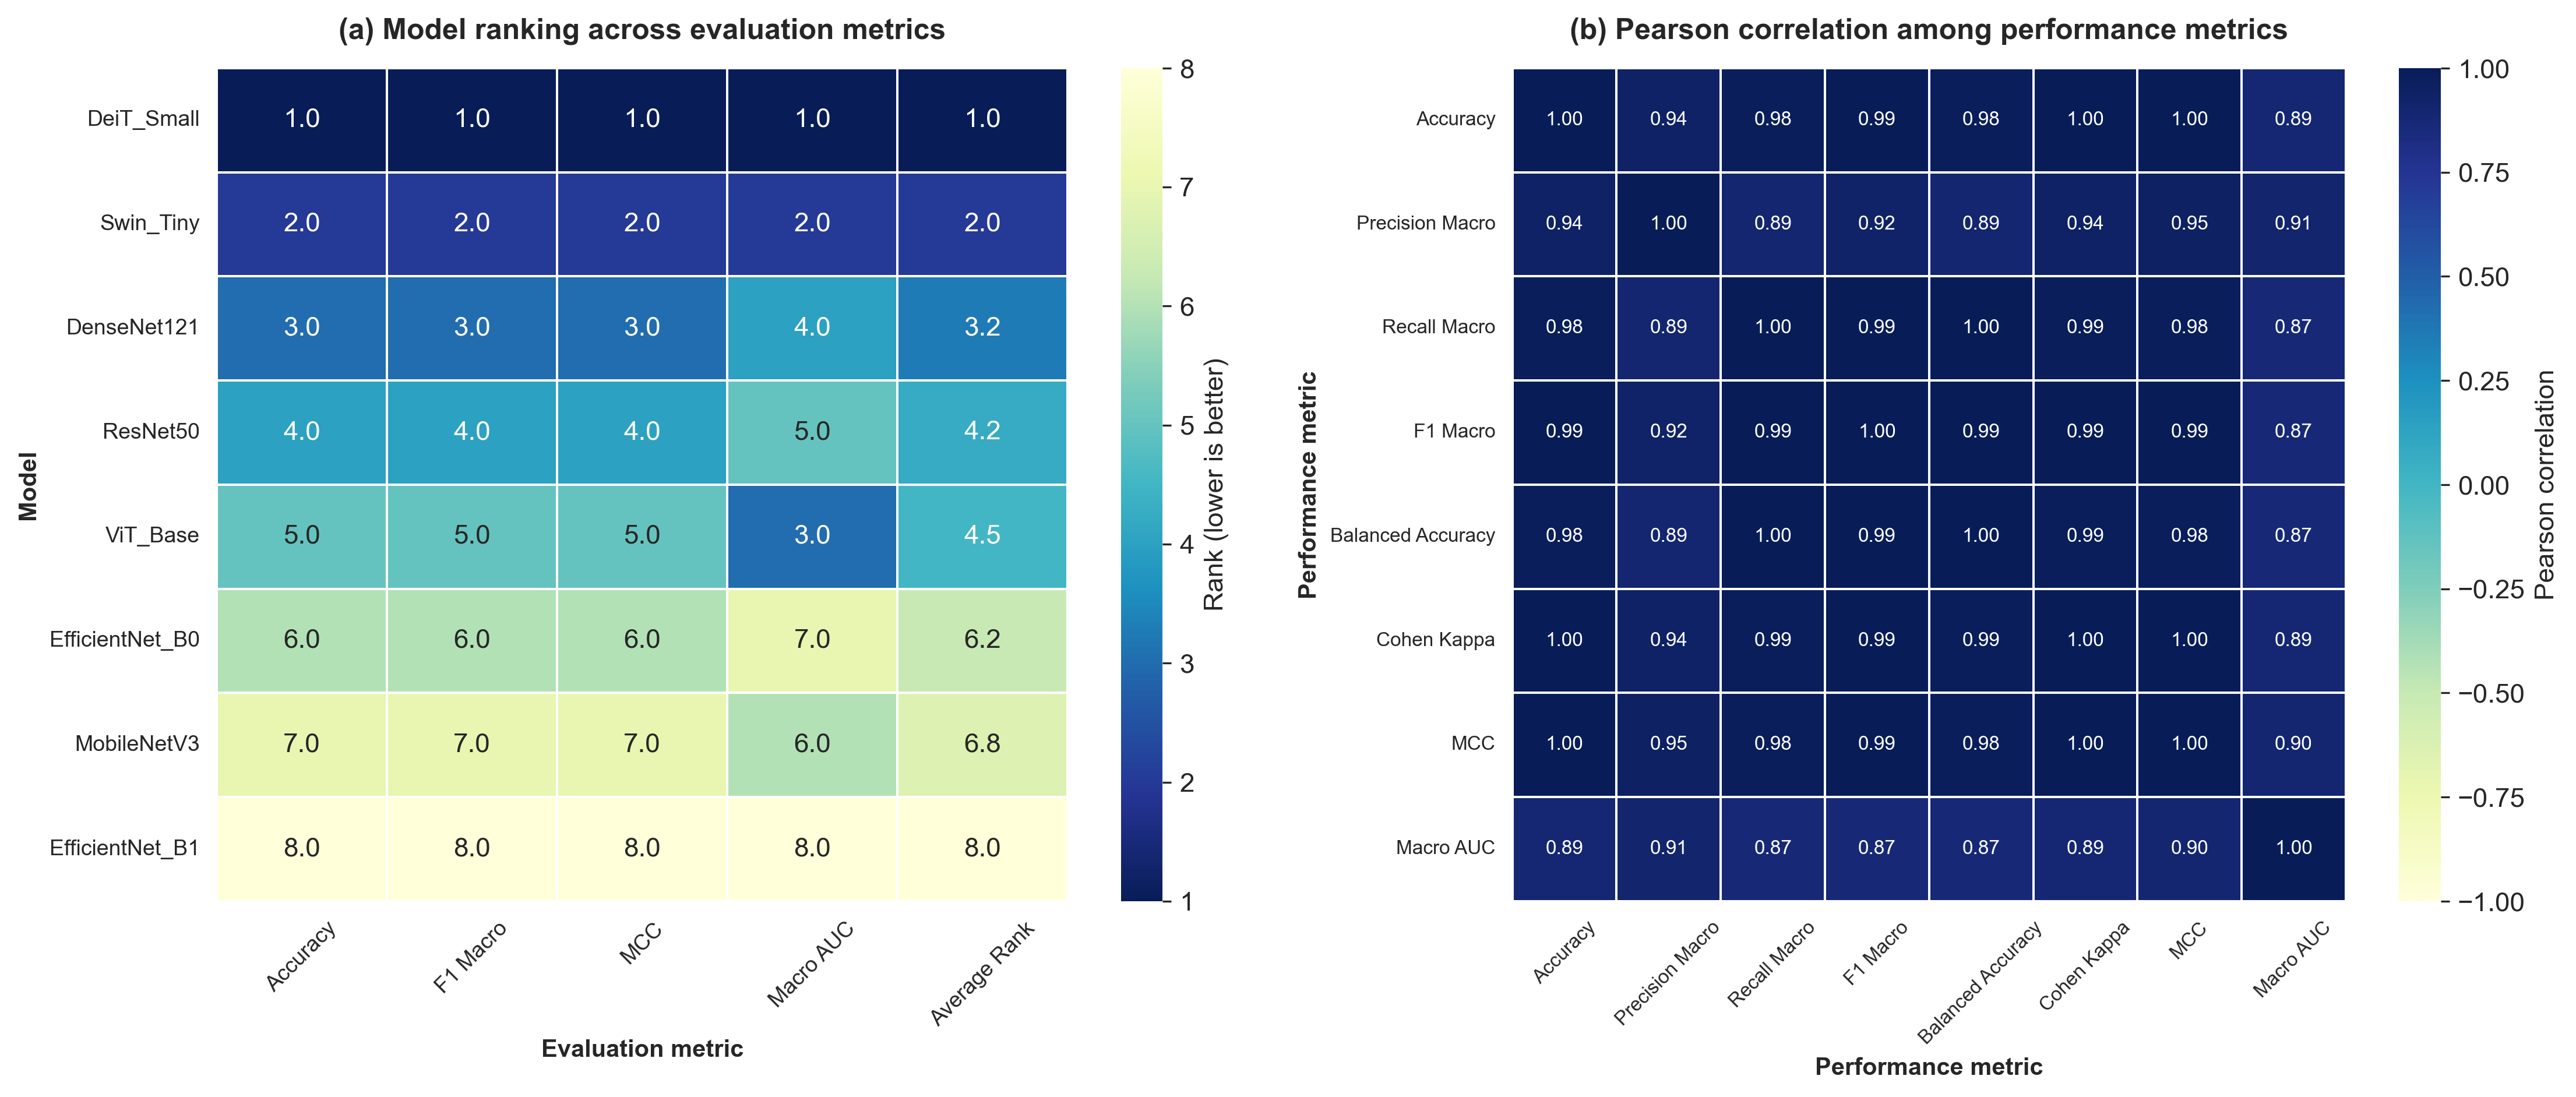


STEP 12-4 + 12-5 COMPLETED SUCCESSFULLY

Ranking table:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_7_Model_Ranking.csv

Correlation matrix:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\01_Tables\Table_S1_Correlation_Matrix.csv

Combined two-panel figure:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Final_Benchmark\02_Figures\Figure_4_Model_Ranking_and_Correlation_Analysis.png


In [35]:
# =============================================================================
# STEP 12-4 + 12-5 : MODEL RANKING + CORRELATION HEATMAP
#                    TWO-PANEL FIGURE
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 80)
print("STEP 12-4 + 12-5 : MODEL RANKING + CORRELATION ANALYSIS")
print("=" * 80)


# =============================================================================
# PART A : MODEL RANKING
# =============================================================================

print("\n[12.4] Calculating model ranking...")


# -----------------------------------------------------------------------------
# Metrics used for model ranking
# -----------------------------------------------------------------------------

ranking_metrics = [
    "Accuracy",
    "F1 Macro",
    "MCC",
    "Macro AUC"
]


# -----------------------------------------------------------------------------
# Check required columns
# -----------------------------------------------------------------------------

missing_ranking = [
    col for col in ranking_metrics
    if col not in master_df.columns
]

if missing_ranking:

    raise KeyError(
        "The following ranking metrics are missing from master_df: "
        f"{missing_ranking}"
    )


# -----------------------------------------------------------------------------
# Mean performance across independent runs
# -----------------------------------------------------------------------------

ranking_mean = (
    master_df
    .groupby("Model")[ranking_metrics]
    .mean()
)


# -----------------------------------------------------------------------------
# Rank models for each metric
#
# Higher performance = better = Rank 1
# -----------------------------------------------------------------------------

ranking_df = ranking_mean.rank(
    ascending=False,
    method="min"
)


# -----------------------------------------------------------------------------
# Average rank
# -----------------------------------------------------------------------------

ranking_df["Average Rank"] = ranking_df.mean(axis=1)


# -----------------------------------------------------------------------------
# Sort according to overall average rank
# -----------------------------------------------------------------------------

ranking_df = ranking_df.sort_values(
    "Average Rank",
    ascending=True
)


# -----------------------------------------------------------------------------
# Save ranking table
# -----------------------------------------------------------------------------

rank_table = ranking_df.round(2)

rank_table_path = (
    TABLES_DIR /
    "Table_7_Model_Ranking.csv"
)

rank_table.to_csv(
    rank_table_path
)


print("\nModel ranking:")
display(rank_table)


# =============================================================================
# PART B : CORRELATION ANALYSIS
# =============================================================================

print("\n[12.5] Calculating Pearson correlation matrix...")


# -----------------------------------------------------------------------------
# Performance metrics used for correlation analysis
# -----------------------------------------------------------------------------

correlation_metrics = [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro",
    "Balanced Accuracy",
    "Cohen Kappa",
    "MCC",
    "Macro AUC"
]


# -----------------------------------------------------------------------------
# Check required columns
# -----------------------------------------------------------------------------

missing_corr = [
    col for col in correlation_metrics
    if col not in master_df.columns
]

if missing_corr:

    raise KeyError(
        "The following correlation metrics are missing from master_df: "
        f"{missing_corr}"
    )


# -----------------------------------------------------------------------------
# Pearson correlation
# -----------------------------------------------------------------------------

corr_matrix = (
    master_df[correlation_metrics]
    .corr(method="pearson")
)


# -----------------------------------------------------------------------------
# Save correlation matrix
# -----------------------------------------------------------------------------

corr_table_path = (
    TABLES_DIR /
    "Table_S1_Correlation_Matrix.csv"
)

corr_matrix.to_csv(
    corr_table_path
)


print("\nCorrelation matrix:")
display(corr_matrix.round(3))


# =============================================================================
# PART C : TWO-PANEL FIGURE
# =============================================================================

print("\nCreating two-panel figure...")


# -----------------------------------------------------------------------------
# Figure
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6.5),
    dpi=300
)


# =============================================================================
# PANEL (a) : MODEL RANKING
# =============================================================================

ax1 = axes[0]


sns.heatmap(
    ranking_df,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu_r",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Rank (lower is better)"
    },
    ax=ax1
)


ax1.set_title(
    "(a) Model ranking across evaluation metrics",
    fontsize=12,
    fontweight="bold",
    pad=12
)


ax1.set_xlabel(
    "Evaluation metric",
    fontsize=10,
    fontweight="bold"
)


ax1.set_ylabel(
    "Model",
    fontsize=10,
    fontweight="bold"
)


ax1.tick_params(
    axis="x",
    labelrotation=45,
    labelsize=9
)


ax1.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=9
)


# =============================================================================
# PANEL (b) : CORRELATION MATRIX
# =============================================================================

ax2 = axes[1]


sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Pearson correlation"
    },
    annot_kws={
        "size": 8
    },
    ax=ax2
)


ax2.set_title(
    "(b) Pearson correlation among performance metrics",
    fontsize=12,
    fontweight="bold",
    pad=12
)


ax2.set_xlabel(
    "Performance metric",
    fontsize=10,
    fontweight="bold"
)


ax2.set_ylabel(
    "Performance metric",
    fontsize=10,
    fontweight="bold"
)


ax2.tick_params(
    axis="x",
    labelrotation=45,
    labelsize=8
)


ax2.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=8
)


# =============================================================================
# OVERALL FIGURE FORMATTING
# =============================================================================

# fig.suptitle(
#     "Model Ranking and Correlation Analysis",
#     fontsize=14,
#     fontweight="bold",
#     y=1.02
# )


plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


# =============================================================================
# SAVE COMBINED FIGURE
# =============================================================================

combined_figure_path = (
    FIGURES_DIR /
    "Figure_4_Model_Ranking_and_Correlation_Analysis.png"
)


fig.savefig(
    combined_figure_path,
    dpi=600,
    bbox_inches="tight"
)


plt.show()


# =============================================================================
# COMPLETION MESSAGE
# =============================================================================

print("\n" + "=" * 80)
print("STEP 12-4 + 12-5 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nRanking table:")
print(rank_table_path)

print("\nCorrelation matrix:")
print(corr_table_path)

print("\nCombined two-panel figure:")
print(combined_figure_path)